Set path to include RStudio packages

In [1]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [2]:
# read /net/home/swolf/Func_Neo_Phytes/Data/tde202616123616.txt, skip first 3 lines, tab delimited
data <- read.table("/net/home/swolf/Func_Neo_Phytes/Data/tde202616123616.txt", skip = 3, header = TRUE, sep = "\t")

In [3]:
# Define the trait data
trait_ids <- c(4, 6, 13, 14, 15, 21, 26, 27, 46, 47, 50, 55, 78, 95, 138, 144, 145, 146, 163, 169, 
               223, 224, 237, 281, 282, 289, 297, 351, 614, 1080, 3086, 3106, 3107, 3108, 3109, 
               3110, 3111, 3112, 3113, 3114, 3115, 3116, 3117, 3120)

In [4]:
filtered_data <- data[data$TraitID %in% trait_ids, ]

In [5]:
# sort data by ObsNum, inverted
filtered_data <- filtered_data[order(-filtered_data$ObsNum), ]
filtered_data


,TraitID,Trait,ObsNum,ObsGRNum,AccSpecNum,X
,<int>,<chr>,<int>,<int>,<int>,<lgl>
1724,3106,Plant height vegetative,368479,268607,35466,NA
2064,26,Seed dry mass,317501,27134,43227,NA
1031,47,"Leaf dry mass per leaf fresh mass (leaf dry matter content, LDMC)",293469,277713,9688,NA
944,3117,"Leaf area per leaf dry mass (specific leaf area, SLA or 1/LMA): undefined if petiole is in- or exclu",249181,206176,16599,NA
2315,21,Stem diameter,215415,199436,8426,NA
1024,55,Leaf dry mass (single leaf),177383,151623,8696,NA
1143,14,Leaf nitrogen (N) content per leaf dry mass,165142,142471,13621,NA
1273,46,Leaf thickness,126654,116389,7773,NA
1319,3120,Leaf water content per leaf dry mass (not saturated),114633,114633,3608,NA


## Load Data

In [6]:

# read the aggregated shapefile
library(sf)
wwf_aggregated <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp")


Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE



Reading layer `wwf_terr_ecos_aggregated' from data source 
  `/net/home/swolf/iNaturalist/Data/WWF/wwf_terr_ecos_aggregated.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 64 features and 1 field
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -87.26008 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84


In [7]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [8]:
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_summary_stats_inkl_pca_mean_group.csv")
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_summary_stats_inkl_pca_mean_group.csv")
#combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_s1_5000_wcvp_all_summary_stats_inkl_pca_mean_group.csv")
combined_data = fread("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_group_log10.csv")



head(combined_data)



h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,27.280,0.523,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,27.200,0.542,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,27.261,0.532,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,27.287,0.556,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,27.500,0.528,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,27.537,0.553,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460


In [9]:
# Trait names

# Define the trait data
trait_ids <- c(4, 6, 13, 14, 15, 21, 26, 27, 46, 47, 50, 55, 78, 95, 138, 144, 145, 146, 163, 169, 
               223, 224, 237, 281, 282, 289, 297, 351, 614, 1080, 3086, 3106, 3107, 3108, 3109, 
               3110, 3111, 3112, 3113, 3114, 3115, 3116, 3117, 3120)

trait_names <- c(
  "Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density", "Root rooting depth", 
  "Leaf carbon (C) content per leaf dry mass", "Leaf nitrogen (N) content per leaf dry mass", 
  "Leaf phosphorus (P) content per leaf dry mass", "Stem diameter", "Seed dry mass", "Seed length", 
  "Leaf thickness", "Leaf dry mass per leaf fresh mass (leaf dry matter content, LDMC)", 
  "Leaf nitrogen (N) content per leaf area", "Leaf dry mass (single leaf)", 
  "Leaf nitrogen (N) isotope signature (delta 15N)", "Seed germination rate (germination efficiency)", 
  "Seed number per reproduction unit", "Leaf length", "Leaf width", "Leaf carbon/nitrogen (C/N) ratio", 
  "Leaf fresh mass", "Stem conduit density (vessels and tracheids)", "Species genotype: chromosome number", 
  "Species genotype: chromosome cDNA content", "Dispersal unit length", "Stem conduit diameter (vessels, tracheids)", 
  "Wood vessel element length; stem conduit (vessel and tracheids) element length", "Wood fiber lengths", 
  "Wood rays per millimetre (wood ray density)", "Seed number per dispersal unit", 
  "Fine root length per fine root dry mass (specific fine root length, SRL)", 
  "Root length per root dry mass (specific root length, SRL)", 
  "Leaf area per leaf dry mass (SLA or 1/LMA) petiole, rhachis and midrib excluded", "Plant height vegetative", 
  "Plant height generative", "Leaf area (in case of compound leaves: leaf, petiole excluded)", 
  "Leaf area (in case of compound leaves: leaflet, petiole excluded)", 
  "Leaf area (in case of compound leaves: leaf, petiole included)", 
  "Leaf area (in case of compound leaves: leaflet, petiole included)", 
  "Leaf area (in case of compound leaves: leaf, undefined if petiole in- or excluded)", 
  "Leaf area (in case of compound leaves: leaflet, undefined if petiole is in- or excluded)", 
  "Leaf area (in case of compound leaves undefined if leaf or leaflet, if petiole is in- or excluded)", 
  "Leaf area per leaf dry mass (SLA or 1/LMA): petiole excluded", 
  "Leaf area per leaf dry mass (SLA or 1/LMA): petiole included", 
  "Leaf area per leaf dry mass (SLA or 1/LMA): undefined if petiole is in- or excluded", 
  "Leaf water content per leaf dry mass (not saturated)"
)


short_names <- c(
  "SSD", 
  "Rooting depth", 
  "Leaf C", 
  "Leaf N", 
  "Leaf P", 
  "Stem diameter", 
  "Seed dry mass", 
  "Seed length", 
  "Leaf thickness", 
  "LDMC", 
  "Leaf N per area", 
  "Leaf dry mass", 
  "Leaf delta 15N", 
  "Germination efficiency", 
  "Seed number/rep. unit", 
  "Leaf length", 
  "Leaf width", 
  "Leaf C/N ratio", 
  "Leaf fresh mass", 
  "Stem conduit density", 
  "Chromosome number", 
  "Chromosome cDNA content", 
  "Dispersal unit length", 
  "Stem conduit diameter", 
  "Wood vessel element length", 
  "Wood fiber lengths", 
  "Wood ray density", 
  "Seed number/disp. unit", 
  "Specific fine root length", 
  "Specific root length", 
  "SLA midrib excl.", 
  "Plant height veg.", 
  "Plant height gen.", 
  "Leaf area 3108 ", 
  "Leaf area 3109", 
  "Leaf area 3110", 
  "Leaf area 3111", 
  "Leaf area 3112", 
  "Leaf area 3113", 
  "Leaf area 3114", 
  "SLA petiole excl.", 
  "SLA petiole incl.", 
  "SLA petiole in- or excluded", 
  "Leaf water content not saturated"
)



sPlotOpen_name <- c(
  "SSD",          # SSD
  "",                      # Rooting depth
  "Leaf.C",  # Leaf C
  "Leaf.N.per.mass",             # Leaf N
  "Leaf.P",             # Leaf P
  "",                      # Stem diameter
  "Seed.mass",          # Seed dry mass
  "Seed.length",       # Seed length
  "",                      # Leaf thickness
  "LDMC",              # LDMC
  "Leaf.N.per.area",      # Leaf N per area
  "",                      # Leaf dry mass
  "Leaf.delta15N",    # Leaf delta 15N
  "",                      # Germination efficiency
  "Seeds.per.rep..unit", # Seed number/rep. unit
  "",                      # Leaf length
  "",                      # Leaf width
  "",       # Leaf C/N ratio
  "Leaf.fresh.mass",     # Leaf fresh mass
  "Stem.conduit.density",    # Stem conduit density
  "",                      # Chromosome number
  "",                      # Chromosome cDNA content
  "Dispersal.unit.length",    # Dispersal unit length
  "",                      # Stem conduit diameter
  "Conduit.element.length",# Wood vessel element length
  "",                      # Wood fiber lengths
  "",                      # Wood ray density
  "",                      # Seed number/disp. unit
  "",                      # Specific fine root length
  "",                      # Specific root length
  "",                      # SLA midrib excl.
  "Plant.Height",       # Plant height veg.
  "",                      # Plant height gen.
  "",                       # Leaf area 3108
  "",                      # Leaf area 3109
  "",                      # Leaf area 3110
  "",                      # Leaf area 3111
  "",                      # Leaf area 3112
  "",                      # Leaf area 3113
  "Leaf.Area",          # Leaf area 3114
  "",                      # SLA petiole excl.
  "",               # SLA petiole incl.
  "SLA",                      # SLA petiole in- or excluded
  ""                       # Leaf water content not saturated
)


unit_names <- c("g/cm3", "m", "mg/g", "mg/g", "mg/g", "m", "mg", "mm", "mm", "g/g", "g m-2", "mg", "per mill", 
                "%", "number", "mm", "cm", "g g-1", "g", "mm-2", "n", "pg", "mm", "micro m", "micro m", 
                "micro m", "1/mm", "number", "cm/g", "cm/g", "mm2/mg", "m", "m", "mm2", "mm2", "mm2", 
                "mm2", "mm2", "mm2", "mm2", "mm2/mg", "mm2/mg", "mm2/mg", "g(W)/g(DM)")

# add "X.X" prefix and "." suffix to TraitID
trait_ids_try6 <- paste0("X.X", trait_ids, ".")

# Create the dataframe
traits <- data.frame(TraitID = trait_ids, TraitID_TRY6 = trait_ids_try6, TraitName = trait_names, ShortName = short_names, sPlotOpenName=sPlotOpen_name, UnitName = unit_names)

# View the dataframe
traits


TraitID,TraitID_TRY6,TraitName,ShortName,sPlotOpenName,UnitName
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
4,X.X4.,"Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density",SSD,SSD,g/cm3
6,X.X6.,Root rooting depth,Rooting depth,,m
13,X.X13.,Leaf carbon (C) content per leaf dry mass,Leaf C,Leaf.C,mg/g
14,X.X14.,Leaf nitrogen (N) content per leaf dry mass,Leaf N,Leaf.N.per.mass,mg/g
15,X.X15.,Leaf phosphorus (P) content per leaf dry mass,Leaf P,Leaf.P,mg/g
21,X.X21.,Stem diameter,Stem diameter,,m
26,X.X26.,Seed dry mass,Seed dry mass,Seed.mass,mg
27,X.X27.,Seed length,Seed length,Seed.length,mm
46,X.X46.,Leaf thickness,Leaf thickness,,mm


In [6]:
write.csv(traits, file="~/Func_Neo_Phytes/Data/trait_info.csv", row.names=FALSE)

In [10]:
library(dplyr)

#traits <- traits %>%
#  mutate(TraitID = as.character(TraitID)) %>%  # Convert TraitID to character
#  dplyr::bind_rows(data.frame(
#    TraitID = c("PC1", "PC2"),
#    TraitID_TRY6 = c("PC1", "PC2"),
#    TraitName = c("Principal Component 1", "Principal Component 2"),
#    ShortName = c("Size spectrum (PC1)", "Economics spectrum (PC2)"),
#   UnitName = c("Dimensionless", "Dimensionless")
#  ))


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [11]:
traits

TraitID,TraitID_TRY6,TraitName,ShortName,sPlotOpenName,UnitName
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
4,X.X4.,"Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density",SSD,SSD,g/cm3
6,X.X6.,Root rooting depth,Rooting depth,,m
13,X.X13.,Leaf carbon (C) content per leaf dry mass,Leaf C,Leaf.C,mg/g
14,X.X14.,Leaf nitrogen (N) content per leaf dry mass,Leaf N,Leaf.N.per.mass,mg/g
15,X.X15.,Leaf phosphorus (P) content per leaf dry mass,Leaf P,Leaf.P,mg/g
21,X.X21.,Stem diameter,Stem diameter,,m
26,X.X26.,Seed dry mass,Seed dry mass,Seed.mass,mg
27,X.X27.,Seed length,Seed length,Seed.length,mm
46,X.X46.,Leaf thickness,Leaf thickness,,mm


In [12]:
leaf_traits <- traits[startsWith(traits$ShortName, "Leaf area"), ]
leaf_traits_ids <- leaf_traits$TraitID_TRY6 
print(leaf_traits_ids)

[1] "X.X3108." "X.X3109." "X.X3110." "X.X3111." "X.X3112." "X.X3113." "X.X3114."


In [13]:
valid_leaf_trait_ids <- leaf_traits_ids[leaf_traits_ids %in% colnames(combined_data)]
valid_leaf_trait_ids

[1] "X.X3112." "X.X3113." "X.X3114."

In [14]:
sla_traits <- traits[startsWith(traits$ShortName, "SLA"), ]
sla_traits_ids <- sla_traits$TraitID_TRY6 
print(sla_traits_ids)

[1] "X.X3086." "X.X3115." "X.X3116." "X.X3117."


In [15]:
valid_sla_trait_ids <- sla_traits_ids[sla_traits_ids %in% colnames(combined_data)]
valid_sla_trait_ids

[1] "X.X3117."

In [16]:
# print colnames of combined_data that start with "X.X" and end with "."
dim(traits)
length(colnames(combined_data)[startsWith(colnames(combined_data), "X.X") & endsWith(colnames(combined_data), ".")])

[1] 44  6

[1] 37


Attaching package: ‘reshape2’


The following objects are masked from ‘package:data.table’:

    dcast, melt




[1] "Correlation matrix for group: native"
          X.X3112.  X.X3113.  X.X3114.
X.X3112. 1.0000000 0.7897221 0.8354094
X.X3113. 0.7897221 1.0000000 0.7143055
X.X3114. 0.8354094 0.7143055 1.0000000
[1] "Correlation matrix for group: all"
          X.X3112.  X.X3113.  X.X3114.
X.X3112. 1.0000000 0.8137161 0.8549028
X.X3113. 0.8137161 1.0000000 0.7442822
X.X3114. 0.8549028 0.7442822 1.0000000


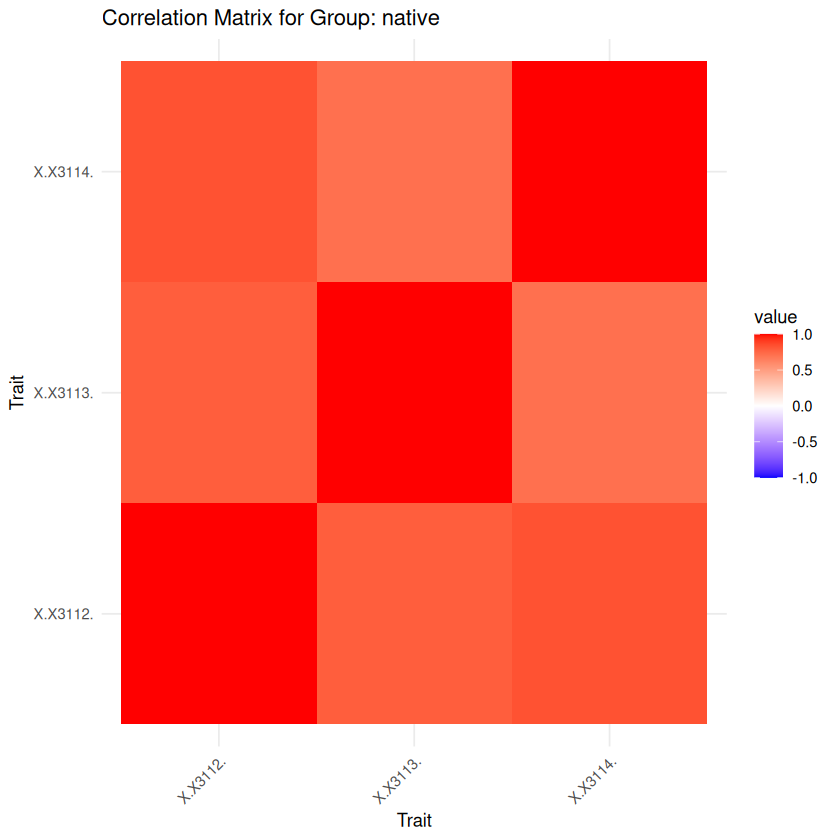

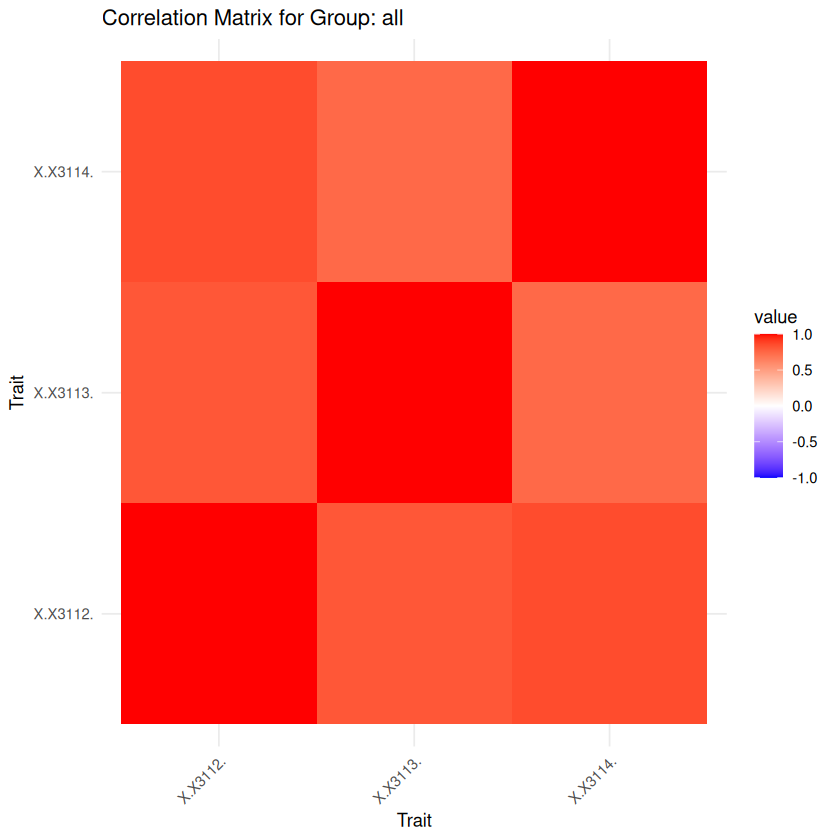

In [14]:
library(ggplot2)
library(dplyr)
library(reshape2)

# Iterate over groups "native" and "all"
for (group in c("native", "all")) {
  # Filter the data for the 7 leaf traits
  leaf_data <- combined_data %>%
    dplyr::select(h3_res3, group, all_of(valid_leaf_trait_ids)) %>%  # Select valid leaf trait columns
    filter(group == !!group) %>%  # Use !! to evaluate the group variable correctly
    na.omit()
  
  # Calculate the correlation matrix
  correlation_matrix <- cor(leaf_data[, valid_leaf_trait_ids, with = FALSE], use = "pairwise.complete.obs")
  print(paste("Correlation matrix for group:", group))
  print(correlation_matrix)
  
  # Melt the correlation matrix for plotting
  correlation_df <- melt(correlation_matrix)
  
  # Plot the correlation matrix
  p <- ggplot(correlation_df, aes(x = Var1, y = Var2, fill = value)) +
    geom_tile() +
    scale_fill_gradient2(low = "blue", high = "red", mid = "white", midpoint = 0, limit = c(-1, 1)) +
    labs(title = paste("Correlation Matrix for Group:", group), x = "Trait", y = "Trait") +
    theme_minimal() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))

   print(p)
   }


In [17]:
head(combined_data)

h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,27.280,0.523,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,27.200,0.542,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,27.261,0.532,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,27.287,0.556,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,27.500,0.528,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,27.537,0.553,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460


In [18]:
# Load necessary libraries
library(sf)
library(h3)
library(dplyr)
# Step 1: Iterate over all regions in the IPCC dataset
for (region in unique(wwf_aggregated$bim_rlm)) {
  # Extract the polygon for the current region
  polygon <- wwf_aggregated[wwf_aggregated$bim_rlm == region, ]
  
  # Convert the polygon to H3 cells (Resolution 3)
  region_cells <- h3::polyfill(polygon, res = 3)
  
  # Assign the region name to the corresponding cells in combined_data
  combined_data$region[combined_data$h3_res3 %in% region_cells] <- region

}

# Step 2: View the updated combined_data
head(combined_data)



polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has holes

polygon has 

h3_res3,group,PC1,PC2,PC3,PC4,count,X.X3117.,X.X14.,X.X50.,⋯,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,region
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
832830fffffffff,all,-1.803834,0.9603752,-0.05605286,0.28704004,534527,18.214,22.920,1.517,⋯,0.523,3.564,0.076,-0.419,89.707,2.436,3.418,-0.386,0.442,12_NA
832830fffffffff,native,-1.354830,0.1581176,-0.61312183,0.47782598,378645,16.342,21.572,1.552,⋯,0.542,3.533,0.095,-0.376,88.577,2.376,3.351,-0.861,0.471,12_NA
832834fffffffff,all,-1.781438,0.5006442,-0.16618360,0.48394999,449715,17.946,22.496,1.543,⋯,0.532,3.556,0.075,-0.395,89.730,2.458,3.400,-0.478,0.453,5_NA
832834fffffffff,native,-1.299022,-0.2982885,-0.69903004,0.65921448,334995,15.877,21.214,1.582,⋯,0.556,3.531,0.091,-0.339,88.691,2.388,3.324,-0.897,0.478,5_NA
832831fffffffff,all,-1.976354,0.9112940,-0.61732579,-0.06457907,64487,18.615,21.891,1.429,⋯,0.528,3.573,0.073,-0.409,89.313,2.452,3.388,-0.634,0.442,NA
832831fffffffff,native,-1.591604,0.3624014,-1.12528671,0.03630553,51697,17.566,20.829,1.440,⋯,0.553,3.543,0.085,-0.383,88.553,2.387,3.333,-1.049,0.460,NA


## Significance Test for Trait shifts

In [19]:
trait_columns <- colnames(combined_data)[startsWith(colnames(combined_data), "X")]
#trait_columns <- c(trait_columns, "PC1", "PC2")

unpaired_wilcoxon_results <- combined_data %>%
    group_by(region) %>%
    summarise(
        across(
            all_of(trait_columns),
            ~ {
                group_all <- .x[group == "all"]
                group_native <- .x[group == "native"]
                if (length(na.omit(group_all)) > 1 && length(na.omit(group_native)) > 1) {
                    wilcox.test(group_all, group_native, paired = FALSE)$p.value
                } else {
                    NA  # Return NA if there are not enough observations
                }
            },
            .names = "wilcox_p_value_{col}"
        )
    )

Warning message:
“There were 605 warnings in `summarise()`.
The first warning was:
ℹ In argument: `across(...)`.
ℹ In group 20: `region = "14_AT"`.
Caused by warning in `wilcox.test.default()`:
! cannot compute exact p-value with ties
ℹ Run `dplyr::last_dplyr_warnings()` to see the 604 remaining warnings.”


In [20]:
# new df with adjusted p-values from unpaired_wilcoxon_results as * ** and *** and ns
significance_levels <- unpaired_wilcoxon_results %>%
    mutate(across(
        starts_with("wilcox_p_value_"),
        ~ p.adjust(.x, method = "BH"),
        .names = "adjusted_{col}"
    )) %>%
    mutate(across(
        starts_with("adjusted_wilcox_p_value_"),
        ~ case_when(
            .x <= 0.001 ~ "***",
            .x <= 0.01 ~ "**",
            .x <= 0.05 ~ "*",
            TRUE ~ ""
        ),
        .names = "sig_{col}"
    )) %>%
    dplyr::select(region, starts_with("sig_"))

In [21]:
# remove from significance_levels columns names the pattern "sig_adjusted_wilcox_p_value_" 
significance_levels <- significance_levels %>%
    rename_with(~ gsub("sig_adjusted_wilcox_p_value_", "", .), starts_with("sig_adjusted_wilcox_p_value_"))
    


In [22]:
significance_levels <- as.data.frame(significance_levels)
significance_levels

region,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,X.X21.,X.X13.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
10_AA,,,,,,,,,,⋯,,,,,,,,,,
10_AT,,***,,,,,,,,⋯,,,,,,**,,,,
10_IM,,,,,,,,,,⋯,,,,,,,,,,
10_NT,,*,,,,,,,,⋯,,,,,,,,,,
10_PA,,,,,,,,,,⋯,,,,,,,,,,
11_NA,,,,,,,,,,⋯,,,,,,,,,,
11_PA,,,,,,,,,,⋯,,,,,,,,,,
12_AA,,,,,,,,,,⋯,,,,,,,,,,
12_AT,,,,,,,,,,⋯,,,,,,,,,,


## Effect Sizes

In [23]:
library(dplyr)
library(effsize) # For Cliff's Delta

# Initialize an empty list to store results
cliffs_delta_results <- list()

# Get all trait columns that start with "X"
trait_columns <- colnames(combined_data)[startsWith(colnames(combined_data), "X")]

# Loop over all unique regions in combined_data
for (current_region in unique(combined_data$region)) {
    # Filter data for the current region
    filtered_data <- combined_data %>%
        filter(region == current_region & group %in% c("all", "native"))
    
    # Skip if there is insufficient data for the test
    if (nrow(filtered_data) < 2) {
        next
    }
    
    # Initialize a list to store Cliff's Delta for each trait
    region_results <- list()
    
    # Loop over all trait columns
    for (trait in trait_columns) {
        # Calculate Cliff's Delta for the current trait
        cliffs_delta <- tryCatch(
            {
                effsize::cliff.delta(
                    filtered_data[[trait]][filtered_data$group == "all"],
                    filtered_data[[trait]][filtered_data$group == "native"]
                )$estimate
            },
            error = function(e) NA
        )
        
        # Store the result
        region_results[[trait]] <- cliffs_delta
    }
    
    # Combine results for the current region into a data frame
    cliffs_delta_results[[current_region]] <- data.frame(
        region = current_region,
        t(region_results)  # Transpose the list to create columns for each trait
    )
}

# Combine all results into a single data frame
cliffs_delta_results_df <- bind_rows(cliffs_delta_results)
# Rename columns to include "effect_" prefix, except for the "region" column
colnames(cliffs_delta_results_df)[-1] <- paste0("effect_", colnames(cliffs_delta_results_df)[-1])

cliffs_delta_results_df


Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence I

region,effect_X.X3117.,effect_X.X14.,effect_X.X50.,effect_X.X146.,effect_X.X3120.,effect_X.X224.,effect_X.X297.,effect_X.X21.,effect_X.X13.,⋯,effect_X.X223.,effect_X.X237.,effect_X.X614.,effect_X.X351.,effect_X.X6.,effect_X.X95.,effect_X.X138.,effect_X.X1080.,effect_X.X78.,effect_X.X4.
<chr>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,⋯,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>
12_NA,0.5867769,0.7520661,-0.2892562,-0.6198347,0.8512397,0.3719008,-0.2066116,-0.3801653,-0.2892562,⋯,0.07438017,-0.2561983,0.5454545,-0.3801653,-0.5785124,0.6694215,0.8181818,0.8181818,0.553719,-0.8595041
5_NA,0.1206371,0.4493075,0.02468144,-0.4081717,0.3303601,-0.04955679,-0.02224377,-0.1700277,-0.1665928,⋯,-0.07542936,-0.1168698,0.06224377,-0.1632133,-0.01595568,0.3464543,0.1130471,0.1851801,0.1885319,-0.2058453
8_NA,0.2023037,0.7365576,-0.008643102,-0.6296207,0.3604965,-0.05690329,0.1037172,-0.1149429,-0.284637,⋯,-0.2172311,-0.211911,0.02028202,0.04492003,-0.03994422,0.4921231,0.4228233,0.3072433,0.2734974,-0.2156471
4_NA,0.003193587,0.4222179,0.3018904,-0.4781593,0.1500343,-0.1375814,-0.1672882,-0.3436,-0.1935014,⋯,-0.2823431,-0.2813143,-0.03326475,-0.151749,0.01451046,0.6731396,0.3159937,0.2560228,0.2131344,-0.208119
1_AT,0.1437103,0.166075,-0.02041937,-0.1092385,0.01163399,0.05902143,0.0929274,-0.1429065,-0.01185771,⋯,-0.1189276,-0.01166721,0.07497776,-0.05817166,-0.09807053,0.08261293,0.02824859,0.0008071807,-0.01094315,-0.06272134
7_AT,0.1029335,0.1692648,0.01061513,-0.149305,0.05360526,0.01735597,0.0223953,-0.06390368,-0.09130636,⋯,-0.09924445,0.007880173,0.04126214,0.01610638,0.00296846,0.06095976,-0.03272319,-0.02750803,0.04520975,-0.08360799
1_NT,0.07890773,0.1499748,0.02730974,-0.1090377,0.1386901,0.06273773,0.06455943,-0.06809207,-0.1076906,⋯,-0.01456568,-0.01637574,0.0700852,-0.006932831,-0.05487481,0.0563696,0.0526628,0.04745975,0.05634895,-0.1310179
6_NA,0.01919442,0.1337248,0.01954867,-0.1171352,0.09564884,0.005393953,0.004893268,-0.1430341,-0.08006396,⋯,-0.08110929,-0.03135312,-0.008869455,-0.04519292,0.07857843,0.1311091,0.0723053,0.06437566,0.1024128,-0.01789627
13_NA,0.1856728,0.1871433,-0.06253282,-0.2042996,0.2127026,-0.002170792,-0.04415112,-0.07471727,-0.1470887,⋯,-0.002590946,-0.1019222,0.04180526,0.03270194,-0.04936802,0.2112321,0.2570288,0.2365113,0.09484962,-0.1247505


In [24]:
library(dplyr)
library(effsize) # For Cliff's Delta

# Initialize an empty list to store results
cliffs_delta_results <- list()

# Get all trait columns that start with "X"
trait_columns <- colnames(combined_data)[startsWith(colnames(combined_data), "X")]

# Loop over all unique regions in combined_data
for (current_region in unique(combined_data$region)) {
    # Filter data for the current region
    filtered_data <- combined_data %>%
        filter(region == current_region & group %in% c("all", "native"))
    
    # Skip if there is insufficient data for the test
    if (nrow(filtered_data) < 2) {
        next
    }
    
    # Initialize a list to store Cliff's Delta for each trait
    region_results <- list()
    
    # Loop over all trait columns
    for (trait in trait_columns) {
        # Calculate Cliff's Delta for the current trait
        cliffs_delta <- tryCatch(
            {
                effsize::cliff.delta(
                    filtered_data[[trait]][filtered_data$group == "all"],
                    filtered_data[[trait]][filtered_data$group == "native"]
                )$estimate
            },
            error = function(e) NA
        )
        
        # Store the result
        region_results[[trait]] <- cliffs_delta
    }
    
    # Combine results for the current region into a data frame
    cliffs_delta_results[[current_region]] <- data.frame(
        region = current_region,
        t(region_results)  # Transpose the list to create columns for each trait
    )
}

# Combine all results into a single data frame
cliffs_delta_results_df <- bind_rows(cliffs_delta_results)
# Rename columns to include "effect_" prefix, except for the "region" column
colnames(cliffs_delta_results_df)[-1] <- paste0("effect_", colnames(cliffs_delta_results_df)[-1])

cliffs_delta_results_df


Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence I

region,effect_X.X3117.,effect_X.X14.,effect_X.X50.,effect_X.X146.,effect_X.X3120.,effect_X.X224.,effect_X.X297.,effect_X.X21.,effect_X.X13.,⋯,effect_X.X223.,effect_X.X237.,effect_X.X614.,effect_X.X351.,effect_X.X6.,effect_X.X95.,effect_X.X138.,effect_X.X1080.,effect_X.X78.,effect_X.X4.
<chr>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,⋯,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>,<named list>
12_NA,0.5867769,0.7520661,-0.2892562,-0.6198347,0.8512397,0.3719008,-0.2066116,-0.3801653,-0.2892562,⋯,0.07438017,-0.2561983,0.5454545,-0.3801653,-0.5785124,0.6694215,0.8181818,0.8181818,0.553719,-0.8595041
5_NA,0.1206371,0.4493075,0.02468144,-0.4081717,0.3303601,-0.04955679,-0.02224377,-0.1700277,-0.1665928,⋯,-0.07542936,-0.1168698,0.06224377,-0.1632133,-0.01595568,0.3464543,0.1130471,0.1851801,0.1885319,-0.2058453
8_NA,0.2023037,0.7365576,-0.008643102,-0.6296207,0.3604965,-0.05690329,0.1037172,-0.1149429,-0.284637,⋯,-0.2172311,-0.211911,0.02028202,0.04492003,-0.03994422,0.4921231,0.4228233,0.3072433,0.2734974,-0.2156471
4_NA,0.003193587,0.4222179,0.3018904,-0.4781593,0.1500343,-0.1375814,-0.1672882,-0.3436,-0.1935014,⋯,-0.2823431,-0.2813143,-0.03326475,-0.151749,0.01451046,0.6731396,0.3159937,0.2560228,0.2131344,-0.208119
1_AT,0.1437103,0.166075,-0.02041937,-0.1092385,0.01163399,0.05902143,0.0929274,-0.1429065,-0.01185771,⋯,-0.1189276,-0.01166721,0.07497776,-0.05817166,-0.09807053,0.08261293,0.02824859,0.0008071807,-0.01094315,-0.06272134
7_AT,0.1029335,0.1692648,0.01061513,-0.149305,0.05360526,0.01735597,0.0223953,-0.06390368,-0.09130636,⋯,-0.09924445,0.007880173,0.04126214,0.01610638,0.00296846,0.06095976,-0.03272319,-0.02750803,0.04520975,-0.08360799
1_NT,0.07890773,0.1499748,0.02730974,-0.1090377,0.1386901,0.06273773,0.06455943,-0.06809207,-0.1076906,⋯,-0.01456568,-0.01637574,0.0700852,-0.006932831,-0.05487481,0.0563696,0.0526628,0.04745975,0.05634895,-0.1310179
6_NA,0.01919442,0.1337248,0.01954867,-0.1171352,0.09564884,0.005393953,0.004893268,-0.1430341,-0.08006396,⋯,-0.08110929,-0.03135312,-0.008869455,-0.04519292,0.07857843,0.1311091,0.0723053,0.06437566,0.1024128,-0.01789627
13_NA,0.1856728,0.1871433,-0.06253282,-0.2042996,0.2127026,-0.002170792,-0.04415112,-0.07471727,-0.1470887,⋯,-0.002590946,-0.1019222,0.04180526,0.03270194,-0.04936802,0.2112321,0.2570288,0.2365113,0.09484962,-0.1247505


In [25]:
# filter effect_sizes based on significance_levels that are "*", "**", or "***"
filtered_effect_sizes <- cliffs_delta_results_df %>%
    left_join(significance_levels, by = "region") %>%
    mutate(across(
        starts_with("effect_"),
        ~ {
            sig_col <- paste0(gsub("effect_", "", cur_column()))
            sig_values <- get(sig_col)
            ifelse(sig_values %in% c("*", "**", "***"), .x, NA  )
        }
    ))

# remove columns that start with "X"
filtered_effect_sizes <- filtered_effect_sizes %>%
    dplyr::select(region, starts_with("effect_"))

# remove "effect_" prefix from column names
colnames(filtered_effect_sizes)[-1] <- gsub("effect_", "", colnames(filtered_effect_sizes)[-1])


filtered_effect_sizes

region,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,X.X21.,X.X13.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<list>,<list>,<list>,<list>,<list>,<list>,<lgl>,<list>,<list>,⋯,<list>,<list>,<list>,<list>,<list>,<list>,<list>,<list>,<list>,<list>
12_NA,NA,0.7520661,NA,NA,0.8512397,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,0.6694215,0.8181818,0.8181818,NA,-0.8595041
5_NA,NA,0.4493075,NA,-0.4081717,0.3303601,NA,NA,-0.1700277,-0.1665928,⋯,NA,NA,NA,NA,NA,0.3464543,NA,0.1851801,0.1885319,-0.2058453
8_NA,0.2023037,0.7365576,NA,-0.6296207,0.3604965,NA,NA,NA,-0.284637,⋯,-0.2172311,-0.211911,NA,NA,NA,0.4921231,0.4228233,0.3072433,0.2734974,-0.2156471
4_NA,NA,0.4222179,0.3018904,-0.4781593,0.1500343,NA,NA,-0.3436,-0.1935014,⋯,-0.2823431,-0.2813143,NA,NA,NA,0.6731396,0.3159937,0.2560228,0.2131344,-0.208119
1_AT,NA,0.166075,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
7_AT,0.1029335,0.1692648,NA,-0.149305,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
1_NT,NA,0.1499748,NA,-0.1090377,0.1386901,NA,NA,NA,-0.1076906,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,-0.1310179
6_NA,NA,0.1337248,NA,NA,NA,NA,NA,-0.1430341,NA,⋯,NA,NA,NA,NA,NA,0.1311091,NA,NA,NA,NA
13_NA,0.1856728,0.1871433,NA,-0.2042996,0.2127026,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,0.2112321,0.2570288,0.2365113,NA,NA


## Alluvial Plot

In [26]:
library(tidyr)  # Load the tidyr package

df_long <- significance_levels %>%
    pivot_longer(
        cols = -region,
        names_to = "trait",
        values_to = "signif"
    ) %>%
    filter(signif != "" & !is.na(signif)) %>%   # keep only significant shifts
    mutate(weight = case_when(
        signif == "*" ~ 1,
        signif == "**" ~ 2,
        signif == "***" ~ 3
    ))


In [27]:
library(dplyr)
library(tidyr)

# convert all trait columns from list -> numeric
trait_cols <- grep("^X", names(filtered_effect_sizes), value = TRUE)

filtered_effect_sizes <- filtered_effect_sizes %>%
  mutate(across(all_of(trait_cols), ~ unlist(.)))


In [28]:
library(dplyr)
library(tidyr)

df_long_eff <- filtered_effect_sizes %>%
  pivot_longer(
    cols = all_of(trait_cols),
    names_to = "trait",
    values_to = "effect_size"
  ) %>%
  filter(!is.na(effect_size))   # keep only significant shifts

head(df_long_eff)

region,trait,effect_size
<chr>,<chr>,<dbl>
12_NA,X.X14.,0.7520661
12_NA,X.X3120.,0.8512397
12_NA,X.X15.,0.8512397
12_NA,X.X169.,-0.7190083
12_NA,X.X281.,0.7355372
12_NA,X.X95.,0.6694215


In [29]:
# merge df_long and df_long_eff by region and trait
df_long <- df_long %>%
    left_join(df_long_eff, by = c("region", "trait"))    
head(df_long)

region,trait,signif,weight,effect_size
<chr>,<chr>,<chr>,<dbl>,<dbl>
10_AA,X.X15.,*,1,0.8367347
10_AT,X.X14.,***,3,0.4380018
10_AT,X.X15.,***,3,0.4317411
10_AT,X.X47.,*,1,-0.3000000
10_AT,X.X95.,**,2,0.3718391
10_NT,X.X14.,*,1,0.2458377


In [30]:
# replace trait name with corresponding "ShortName" from traits dataframe
df_long <- df_long %>% left_join(traits %>% dplyr::select(TraitID_TRY6, ShortName), by = c("trait" = "TraitID_TRY6")) %>%
  rename(trait_name = ShortName)

In [135]:
df_long

region,trait,signif,weight,effect_size,trait_name
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
10_AA,X.X15.,*,1,0.8367347,Leaf P
10_AT,X.X14.,***,3,0.4380018,Leaf N
10_AT,X.X15.,***,3,0.4317411,Leaf P
10_AT,X.X47.,*,1,-0.3000000,LDMC
10_AT,X.X95.,**,2,0.3718391,Germination efficiency
10_NT,X.X14.,*,1,0.2458377,Leaf N
10_NT,X.X15.,*,1,0.2909091,Leaf P
10_NT,X.X1080.,*,1,0.2679387,Specific root length
12_NA,X.X14.,**,2,0.7520661,Leaf N


In [31]:
# number of unique regions and traits with significant shifts
num_regions <- length(unique(df_long$region))
num_traits <- length(unique(df_long$trait))
num_regions 
num_traits


[1] 28

[1] 36

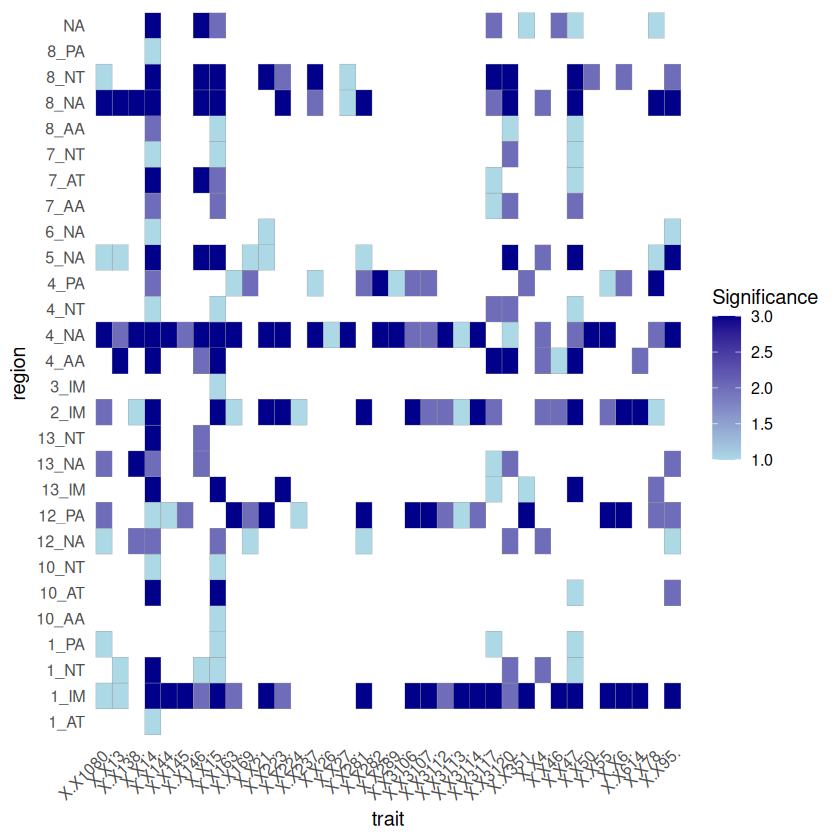

In [32]:
library(ggplot2)
library(dplyr)

df_plot <- df_long %>%
  mutate(signif_num = case_when(
    signif == "*" ~ 1,
    signif == "**" ~ 2,
    signif == "***" ~ 3
  ))

p <- ggplot(df_plot, aes(trait, region, fill = signif_num)) +
  geom_tile(color = "grey60") +
  scale_fill_gradient(
    name = "Significance", 
    low = "lightblue", 
    high = "darkblue"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    panel.grid.major = element_blank(),  # Remove default grid lines
    panel.grid.minor = element_blank()   # Remove minor grid lines
  )
  # Save the plot as a PNG file
  ggsave("~/Func_Neo_Phytes/Results/Figures/trait_significance_heatmap_log10.png", plot = p, width = 10, height = 9, dpi = 300)

print(p)

In [33]:
head(df_long)

region,trait,signif,weight,effect_size,trait_name
<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
10_AA,X.X15.,*,1,0.8367347,Leaf P
10_AT,X.X14.,***,3,0.4380018,Leaf N
10_AT,X.X15.,***,3,0.4317411,Leaf P
10_AT,X.X47.,*,1,-0.3000000,LDMC
10_AT,X.X95.,**,2,0.3718391,Germination efficiency
10_NT,X.X14.,*,1,0.2458377,Leaf N


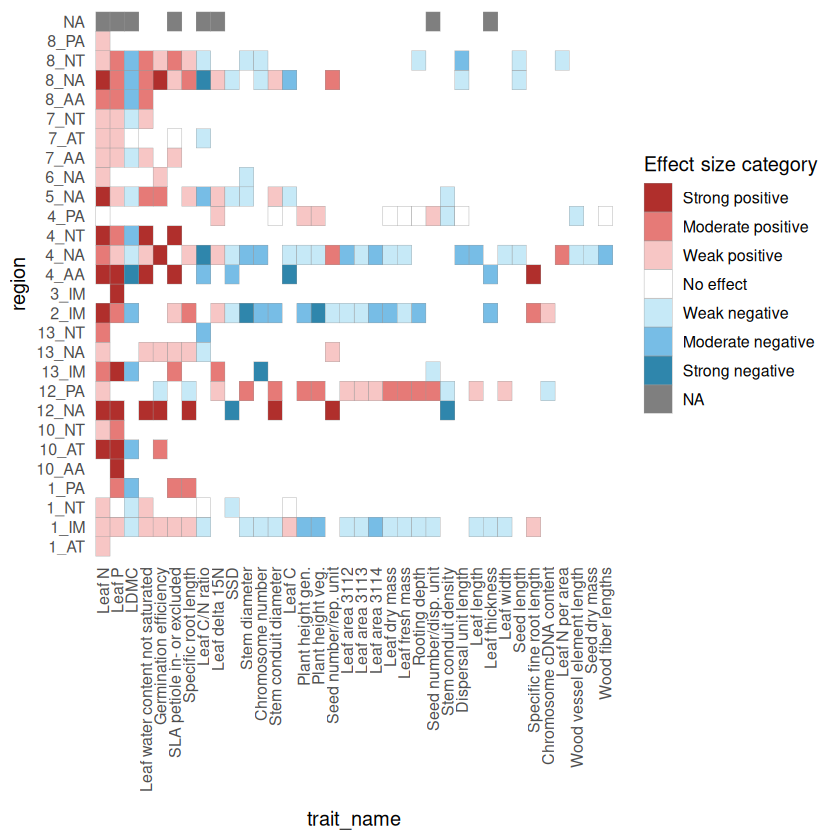

In [34]:
library(ggplot2)
library(dplyr)

df_plot <- df_long %>%
  mutate(effect_size_category = case_when(
      effect_size >= 0.11 & effect_size < 0.28 ~ 1,
      effect_size >= 0.28 & effect_size < 0.43 ~ 2,
      effect_size >= 0.43 ~ 3,
      effect_size > -0.11 & effect_size < 0.11 ~ 0,
      effect_size <= -0.11 & effect_size > -0.28 ~ -1,
      effect_size <= -0.28 & effect_size > -0.43 ~ -2,  
      effect_size <= -0.43 ~ -3
    )) %>%
  group_by(trait_name) %>%
  mutate(non_zero_count = sum(effect_size_category != 0, na.rm = TRUE)) %>%
  ungroup() %>%
  mutate(trait_name = reorder(trait_name, -non_zero_count))  # Sort traits by non-zero count



p <- ggplot(df_plot, aes(trait_name, region, fill = factor(effect_size_category, levels = rev(c("-3", "-2", "-1", "0", "1", "2", "3"))))) +
  geom_tile(color = "grey60") +
  scale_fill_manual(
    name = "Effect size category",
    values = c(
      "-3" = "#2F86AC",  # Strong negative effect
      "-2" = "#77bde6",  # Moderate negative effect
      "-1" = "#c6e9f7",  # Weak negative effect
      "0" = "white",     # No effect
      "1" = "#f7c6c5",   # Weak positive effect
      "2" = "#e67a77",   # Moderate positive effect
      "3" = "#b02f2c"    # Strong positive effect
    ),
    labels = c(
      "-3" = "Strong negative",
      "-2" = "Moderate negative",
      "-1" = "Weak negative",
      "0" = "No effect",
      "1" = "Weak positive",
      "2" = "Moderate positive",
      "3" = "Strong positive"
    )
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),  # Make labels vertical
    panel.grid.major = element_blank(),  # Remove default grid lines
    panel.grid.minor = element_blank()   # Remove minor grid lines
  )
  # Save the plot as a PNG file
  ggsave("~/Func_Neo_Phytes/Results/Figures/trait_effect_heatmap_log10.png", plot = p, width = 10, height = 10, dpi = 300)

print(p)

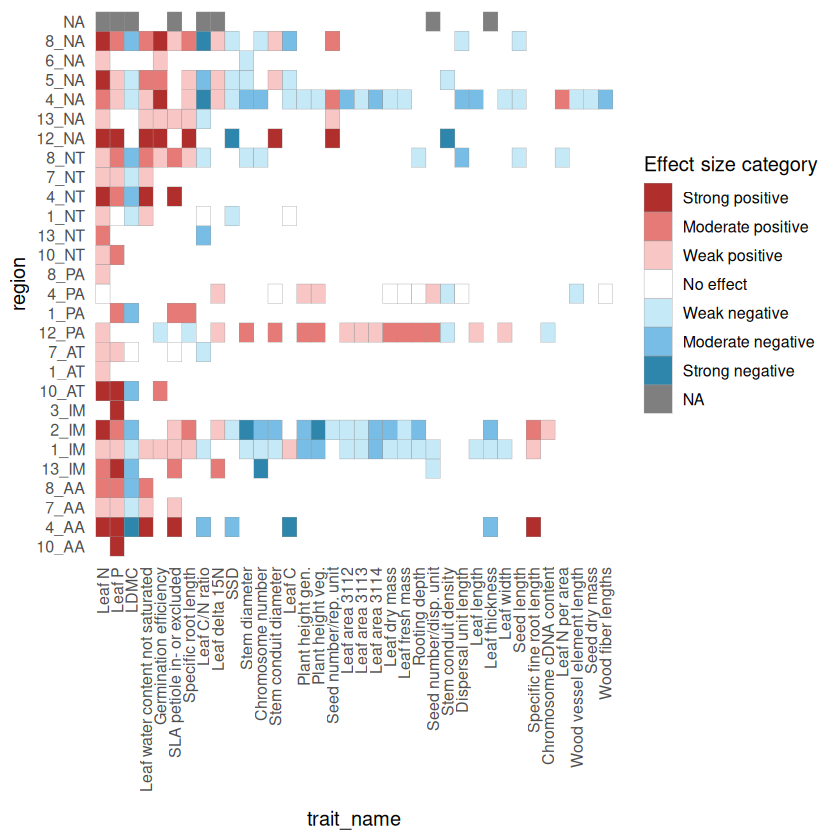

In [35]:

df_plot <- df_long %>%
  mutate(effect_size_category = case_when(
      effect_size >= 0.11 & effect_size < 0.28 ~ 1,
      effect_size >= 0.28 & effect_size < 0.43 ~ 2,
      effect_size >= 0.43 ~ 3,
      effect_size > -0.11 & effect_size < 0.11 ~ 0,
      effect_size <= -0.11 & effect_size > -0.28 ~ -1,
      effect_size <= -0.28 & effect_size > -0.43 ~ -2,  
      effect_size <= -0.43 ~ -3
    )) %>%
  group_by(trait_name) %>%
  mutate(non_zero_count = sum(effect_size_category != 0, na.rm = TRUE)) %>%
  ungroup() %>%
  mutate(trait_name = reorder(trait_name, -non_zero_count))  # Sort traits by non-zero count

library(stringr)  # optional, for str_extract

df_plot <- df_plot %>%
  mutate(region_order = factor(
    sub(".*_", "", region),
    c("AA", "IM", "AT", "PA", "NT", "NA"))) %>%  # Extract and order by specified levels
  mutate(region = factor(region, levels = unique(region[order(region_order)])))  # Reorder factor


p <- ggplot(df_plot, aes(trait_name, region, fill = factor(effect_size_category, levels = rev(c("-3", "-2", "-1", "0", "1", "2", "3"))))) +
  geom_tile(color = "grey60") +
  scale_fill_manual(
    name = "Effect size category",
    values = c(
      "-3" = "#2F86AC",
      "-2" = "#77bde6",
      "-1" = "#c6e9f7",
      "0" = "white",
      "1" = "#f7c6c5",
      "2" = "#e67a77",
      "3" = "#b02f2c"
    ),
    labels = c(
      "-3" = "Strong negative",
      "-2" = "Moderate negative",
      "-1" = "Weak negative",
      "0" = "No effect",
      "1" = "Weak positive",
      "2" = "Moderate positive",
      "3" = "Strong positive"
    )
  ) +
  theme_minimal(base_size = 12) +
  theme(
    axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank()
  )

ggsave("~/Func_Neo_Phytes/Results/Figures/trait_effect_heatmap_log10.png", plot = p, width = 10, height = 10, dpi = 300)
print(p)


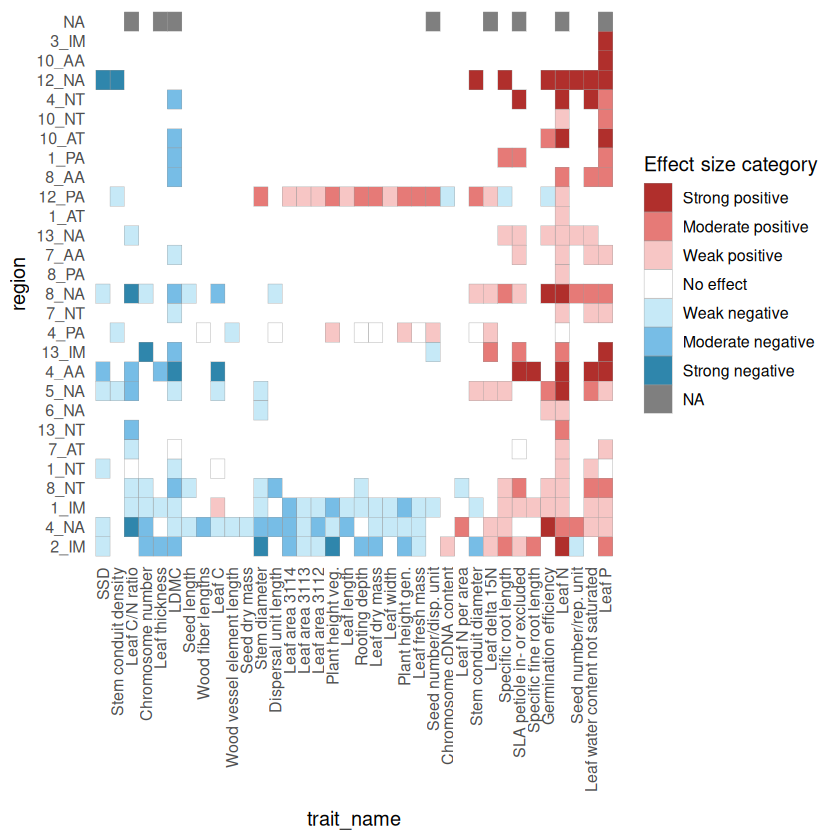

In [36]:
df_plot <- df_plot %>%
  group_by(trait_name) %>%
  mutate(mean_effect_trait = mean(effect_size, na.rm = TRUE)) %>%
  ungroup() %>%
  mutate(trait_name = factor(trait_name, levels = unique(trait_name[order(mean_effect_trait)])))

df_plot <- df_plot %>%
  group_by(region) %>%
  mutate(mean_effect_region = mean(effect_size, na.rm = TRUE)) %>%
  ungroup() %>%
  mutate(region = factor(region, levels = unique(region[order(mean_effect_region)])))

p <- ggplot(df_plot, aes(trait_name, region, fill = factor(effect_size_category, levels = rev(c("-3", "-2", "-1", "0", "1", "2", "3"))))) +
    geom_tile(color = "grey60") +
    scale_fill_manual(
        name = "Effect size category",
        values = c(
            "-3" = "#2F86AC",
            "-2" = "#77bde6",
            "-1" = "#c6e9f7",
            "0" = "white",
            "1" = "#f7c6c5",
            "2" = "#e67a77",
            "3" = "#b02f2c"
        ),
        labels = c(
            "-3" = "Strong negative",
            "-2" = "Moderate negative",
            "-1" = "Weak negative",
            "0" = "No effect",
            "1" = "Weak positive",
            "2" = "Moderate positive",
            "3" = "Strong positive"
        )
    ) +
    theme_minimal(base_size = 12) +
    theme(
        axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5),
        panel.grid.major = element_blank(),
        panel.grid.minor = element_blank()
    )

ggsave("~/Func_Neo_Phytes/Results/Figures/trait_effect_heatmap_sorted_log10.png", plot = p, width = 10, height = 10, dpi = 300)
print(p)


In [28]:
trait_pca <- fread("/net/scratch/swolf/GBIF/trait_pca_glonaf_wcvp_res3_try6_mean_imp_CS.csv")

In [42]:
tp <- trait_pca  # shorthand

# PC1–PC2 plane
tp$angle12_PC1 <- atan(abs(tp$PC2) / abs(tp$PC1)) * 180/pi
tp$angle12_PC2 <- atan(abs(tp$PC1) / abs(tp$PC2)) * 180/pi

# PC2–PC3 plane
tp$angle23_PC2 <- atan(abs(tp$PC3) / abs(tp$PC2)) * 180/pi
tp$angle23_PC3 <- atan(abs(tp$PC2) / abs(tp$PC3)) * 180/pi

# PC1–PC3 plane
tp$angle13_PC1 <- atan(abs(tp$PC3) / abs(tp$PC1)) * 180/pi
tp$angle13_PC3 <- atan(abs(tp$PC1) / abs(tp$PC3)) * 180/pi


In [43]:
which_axis_2d <- function(angle_PCx, angle_PCy, x_name, y_name) {
  if (angle_PCx < 30) return(x_name)
  if (angle_PCy < 30) return(y_name)
  if (angle_PCx < 60 & angle_PCy < 60) return(paste0(x_name, "_", y_name))
  return(NA)  # not strongly represented in this plane
}


In [44]:
tp$plane12_class <- mapply(
  which_axis_2d,
  tp$angle12_PC1, tp$angle12_PC2,
  MoreArgs=list("PC1","PC2")
)

tp$plane23_class <- mapply(
  which_axis_2d,
  tp$angle23_PC2, tp$angle23_PC3,
  MoreArgs=list("PC2","PC3")
)

tp$plane13_class <- mapply(
  which_axis_2d,
  tp$angle13_PC1, tp$angle13_PC3,
  MoreArgs=list("PC1","PC3")
)


In [45]:
tp$axis_contrib <- apply(tp[,c("plane12_class","plane23_class","plane13_class")], 
                         1, function(x) {
                           u <- unique(na.omit(unlist(strsplit(x, "_"))))
                           if (length(u)==0) return("none")
                           paste(sort(u), collapse="_")
                         })


In [46]:
tp

PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,⋯,angle12_PC1,angle12_PC2,angle23_PC2,angle23_PC3,angle13_PC1,angle13_PC3,plane12_class,plane23_class,plane13_class,axis_contrib
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
-0.11771576,0.330017814,0.0583187863,0.111168828,-0.164197232,0.05932541,-0.056294338,0.040827373,-0.003328368,-0.101292961,⋯,70.368928,19.631072,10.021508,79.978492,26.35475232,63.645248,PC2,PC2,PC1,PC1_PC2
-0.05295391,0.234476608,-0.3154628164,0.005303973,-0.153963130,-0.16818616,0.185118641,-0.074052595,-0.054490333,-0.081054442,⋯,77.273883,12.726117,53.377385,36.622615,80.47110913,9.528891,PC2,PC2_PC3,PC3,PC2_PC3
0.08800348,-0.268467526,-0.2224821026,-0.197629815,0.112919926,-0.10549136,0.166826978,-0.114573534,-0.084498149,0.052335639,⋯,71.850889,18.149111,39.648930,50.351070,68.41857264,21.581427,PC2,PC2_PC3,PC3,PC2_PC3
0.03374296,-0.230361057,0.3312286062,0.020067978,0.162218817,0.14324384,-0.197662541,0.100110829,0.045203084,0.006643955,⋯,81.666659,8.333341,55.182371,34.817629,84.18322430,5.816776,PC2,PC2_PC3,PC3,PC2_PC3
-0.16047443,0.276506031,0.0227489241,-0.093454163,0.081013428,-0.04161209,-0.113505027,0.139643882,0.033579150,-0.018613964,⋯,59.870619,30.129381,4.703291,85.296709,8.06851251,81.931487,PC1_PC2,PC2,PC1,PC1_PC2
-0.09206783,0.066948678,0.1972772408,-0.419194151,-0.064524927,-0.11855489,0.230634298,0.085021736,0.188734511,-0.084168338,⋯,36.023408,53.976592,71.254667,18.745333,64.98188671,25.018113,PC1_PC2,PC3,PC3,PC1_PC2_PC3
-0.06726737,-0.040345109,0.2209264515,0.352716108,-0.060583264,-0.07409951,-0.261948927,-0.278947879,-0.036600729,-0.193807537,⋯,30.954164,59.045836,79.650809,10.349191,73.06563055,16.934369,PC1_PC2,PC3,PC3,PC1_PC2_PC3
0.19793121,-0.010530316,0.0758515332,-0.213944561,-0.168733367,-0.20129163,-0.013275374,-0.019985679,-0.049371804,-0.022053314,⋯,3.045373,86.954627,82.096261,7.903739,20.96791628,69.032084,PC1,PC3,PC1,PC1_PC3
0.07763237,-0.186844355,0.2604437776,0.166170320,-0.043817251,0.11082756,0.011155625,-0.074582266,-0.081880400,-0.227970263,⋯,67.437498,22.562502,54.344054,35.655946,73.40187832,16.598122,PC2,PC2_PC3,PC3,PC2_PC3


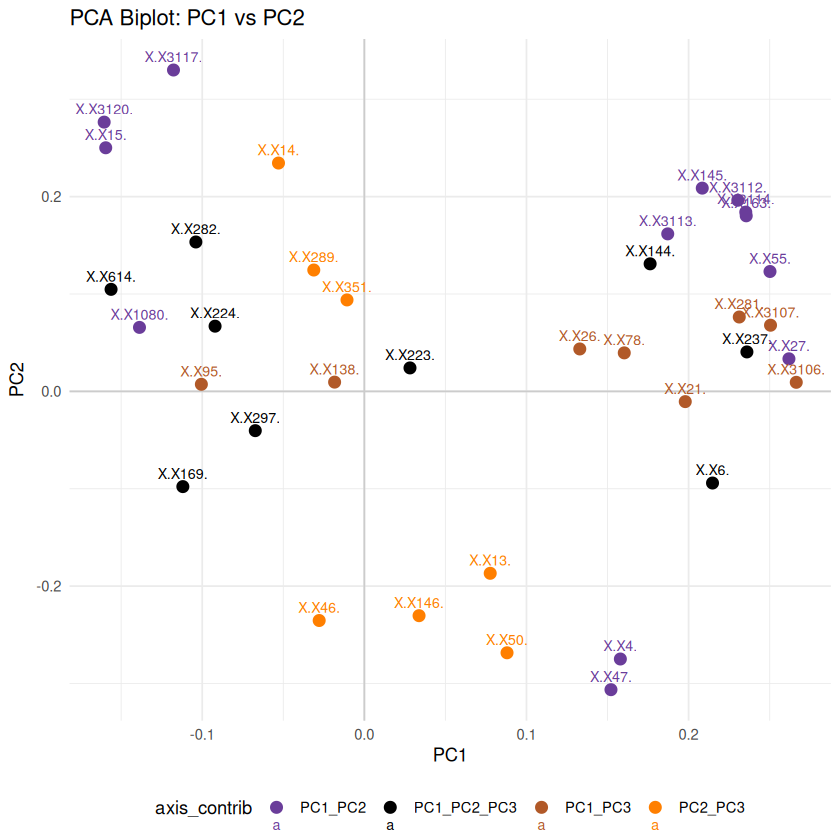

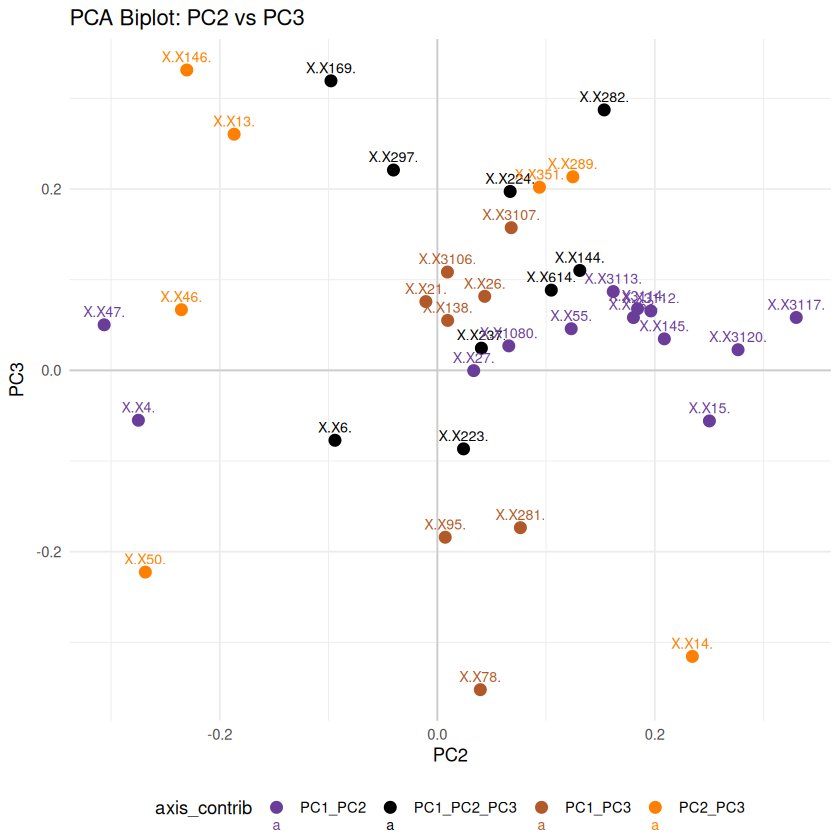

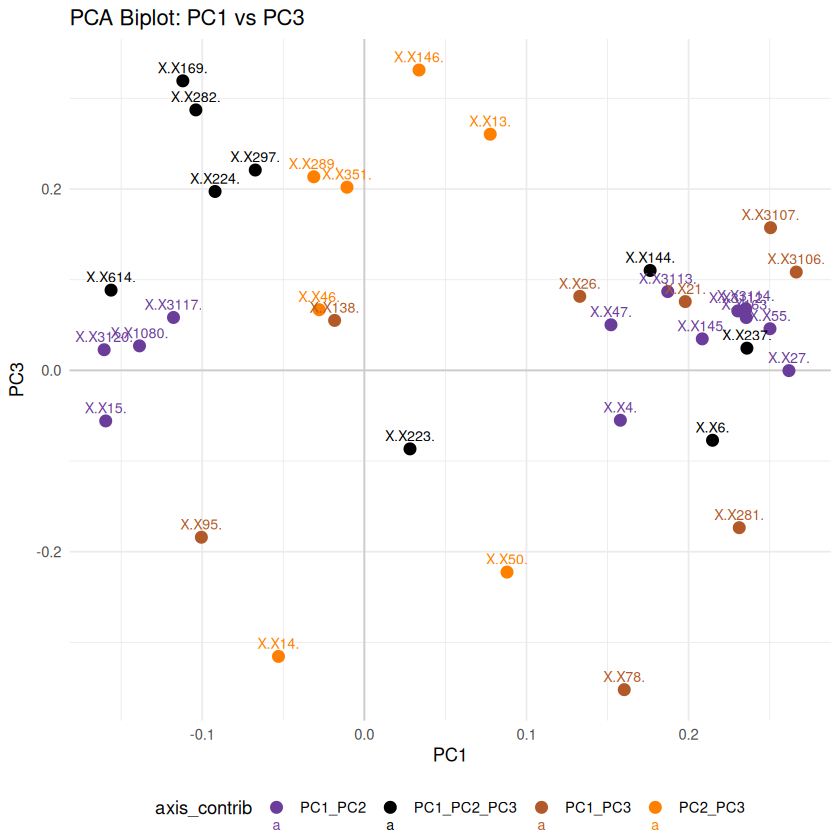

In [47]:
library(ggplot2)

axis_cols <- c(
  "PC1" = "#1f78b4",
  "PC2" = "#33a02c",
  "PC3" = "#e31a1c",
  "PC1_PC2" = "#6a3d9a",
  "PC2_PC3" = "#ff7f00",
  "PC1_PC3" = "#b15928",
  "PC1_PC2_PC3" = "black",
  "none" = "grey70"
)
#
ggplot(tp, aes(PC1, PC2, label = trait, color = axis_contrib)) +
  geom_hline(yintercept = 0, color = "grey80") +
  geom_vline(xintercept = 0, color = "grey80") +
  geom_point(size = 3) +
  geom_text(vjust = -0.7, size = 3) +
  scale_color_manual(values = axis_cols) +
  theme_minimal() +
  ggtitle("PCA Biplot: PC1 vs PC2") +
  theme(legend.position = "bottom")
#2. Biplot: PC2 vs PC3
ggplot(tp, aes(PC2, PC3, label = trait, color = axis_contrib)) +
  geom_hline(yintercept = 0, color = "grey80") +
  geom_vline(xintercept = 0, color = "grey80") +
  geom_point(size = 3) +
  geom_text(vjust = -0.7, size = 3) +
  scale_color_manual(values = axis_cols) +
  theme_minimal() +
  ggtitle("PCA Biplot: PC2 vs PC3") +
  theme(legend.position = "bottom")
#3. Biplot: PC1 vs PC3
ggplot(tp, aes(PC1, PC3, label = trait, color = axis_contrib)) +
  geom_hline(yintercept = 0, color = "grey80") +
  geom_vline(xintercept = 0, color = "grey80") +
  geom_point(size = 3) +
  geom_text(vjust = -0.7, size = 3) +
  scale_color_manual(values = axis_cols) +
  theme_minimal() +
  ggtitle("PCA Biplot: PC1 vs PC3") +
  theme(legend.position = "bottom")

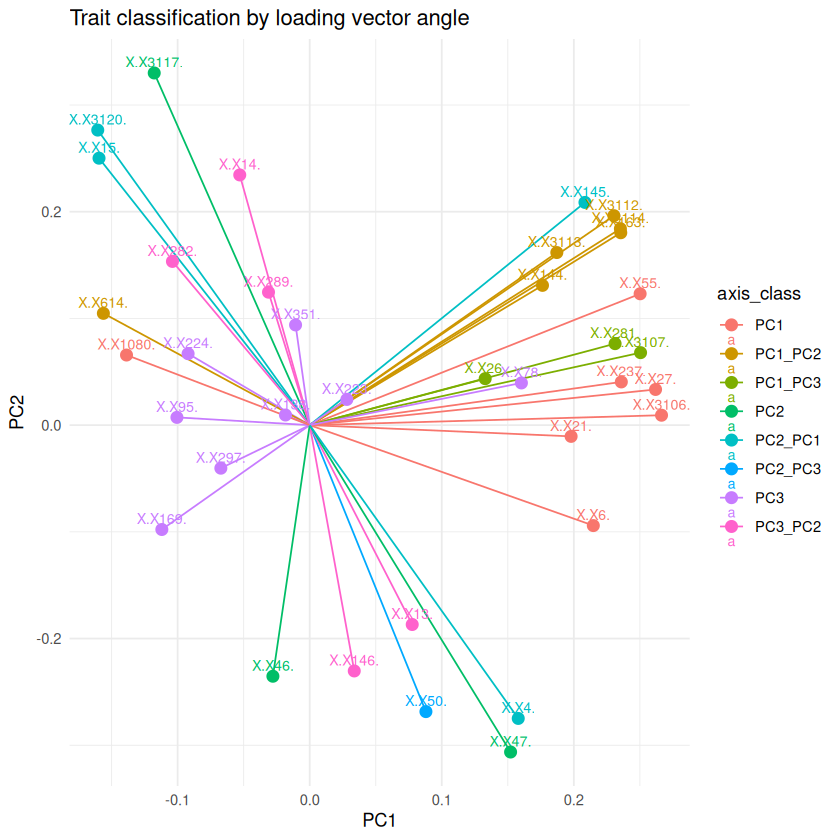

In [40]:
ggplot(trait_pca, aes(PC1, PC2, color = axis_class, label = trait)) +
  geom_segment(aes(x = 0, y = 0, xend = PC1, yend = PC2, color = axis_class), linewidth = 0.5) +
  geom_point(size = 3) +
  geom_text(size = 3, vjust = -0.5) +
  theme_minimal() +
  ggtitle("Trait classification by loading vector angle")


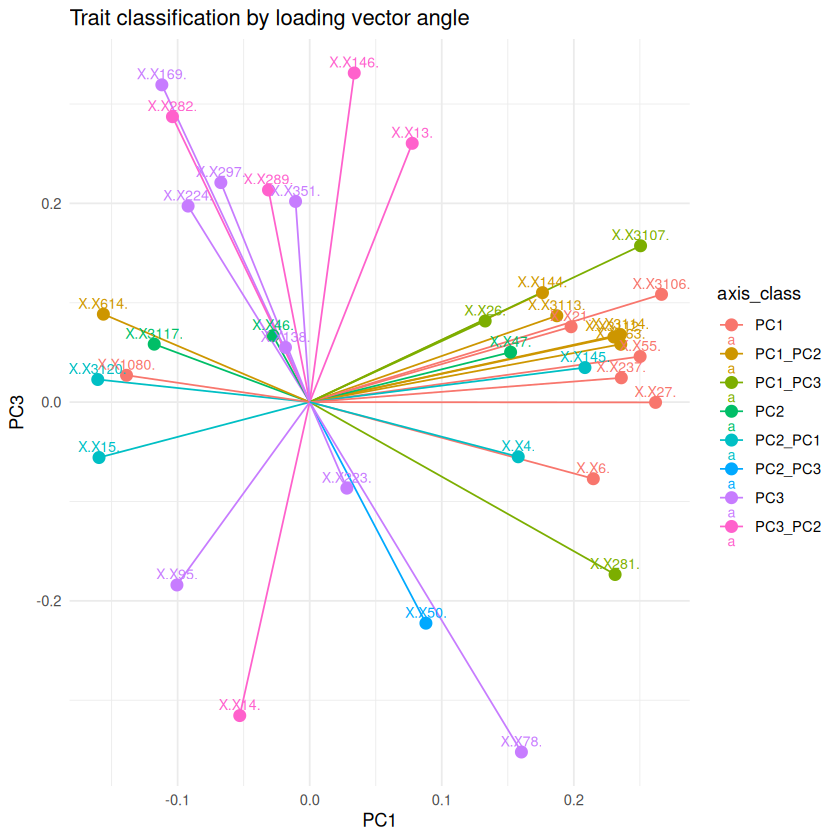

In [41]:
ggplot(trait_pca, aes(PC1, PC3, color = axis_class, label = trait)) +
  geom_segment(aes(x = 0, y = 0, xend = PC1, yend = PC3, color = axis_class), linewidth = 0.5) +
  geom_point(size = 3) +
  geom_text(size = 3, vjust = -0.5) +
  theme_minimal() +
  ggtitle("Trait classification by loading vector angle")


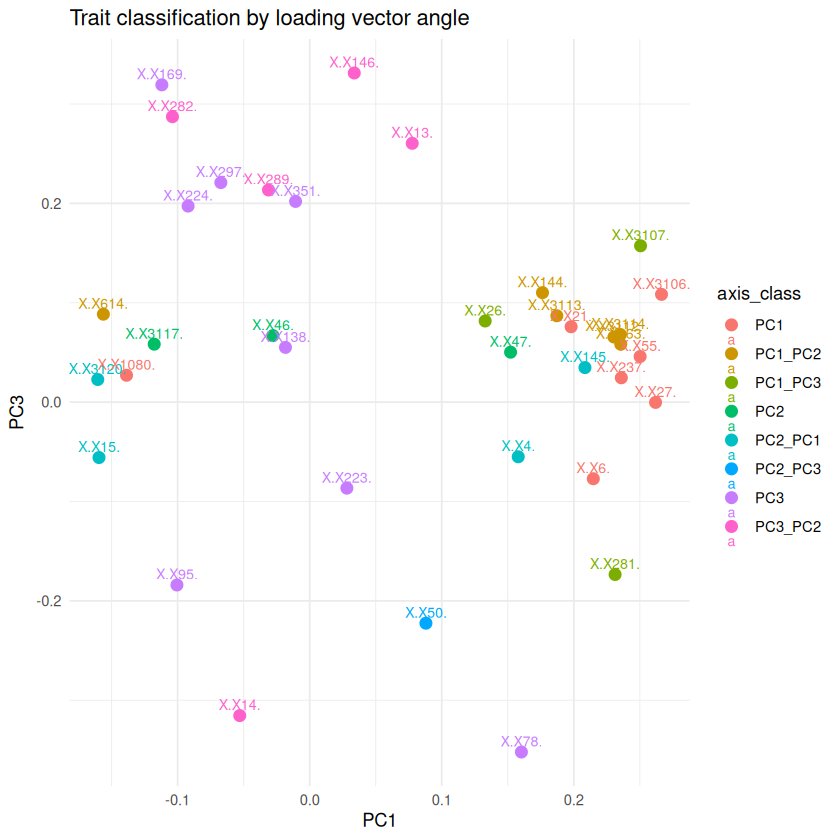

In [32]:
ggplot(trait_pca, aes(PC1, PC3, color = axis_class, label = trait)) +
  geom_point(size = 3) +
  geom_text(size = 3, vjust = -0.5) +
  theme_minimal() +
  ggtitle("Trait classification by loading vector angle")


In [ ]:
library(ggplot2)
library(ggalluvial)

# Define the color mapping for regions
region_colors <- c(
    "10_AT" = "#37a2ee",
    "12_NA" = "#6a3d9a",
    "12_PA" = "#6a3d9a",
    "13_IM" = "#d62728",
    "13_NA" = "#d62728",
    "13_NT" = "#d62728",
    "1_IM" = "#4ae5ce",
    "1_NT" = "#4ae5ce",
    "2_IM" = "#bcbd22",
    "4_AA" = "#33a02c",
    "4_NA" = "#33a02c",
    "4_NT" = "#33a02c",
    "4_PA" = "#33a02c",
    "5_NA" = "#fdbf6f",
    "7_AA" = "#cab2d6",
    "7_AT" = "#cab2d6",
    "7_NT" = "#cab2d6",
    "8_NA" = "#ff7f00",
    "8_NT" = "#ff7f00",
    "8_PA" = "#ff7f00",
    "7_AA" = "#e2def7ff"
)

df_long <- significance_levels %>%
    pivot_longer(
        cols = -region,
        names_to = "trait",
        values_to = "signif"
    ) %>%
    filter(signif != "" & !is.na(signif)) %>%   # keep only significant shifts
    mutate(weight = case_when(
        signif == "*" ~ 1,
        signif == "**" ~ 2,
        signif == "***" ~ 3
    ))
# Sort regions by what comes after "_"
df_long <- df_long %>%
    mutate(region_sort_key = sub(".*_", "", region)) %>%
    arrange(region_sort_key)
    
# Ensure unmapped regions default to light grey
df_long$region_color <- region_colors[df_long$region]
df_long$region_color[is.na(df_long$region_color)] <- "#d3d3d3"

# remove rows with region NA
df_long <- df_long %>%
    filter(!is.na(region))
    
# Sort traits by the number of regions flowing into them
trait_order <- df_long %>%
    group_by(trait) %>%
    summarise(total_weight = sum(weight, na.rm = TRUE)) %>%
    arrange(desc(total_weight)) %>%
    pull(trait)

df_long <- df_long %>%
    mutate(trait = factor(trait, levels = trait_order))

# Plot the alluvial diagram
ggplot(df_long,
       aes(axis1 = region, axis2 = trait, y = weight)) +
    geom_alluvium(aes(fill = region_color), width = 1/12) +
    geom_stratum(width = 1/12, fill = "grey80") +
    geom_label(stat = "stratum",
               aes(label = after_stat(stratum))) +
    scale_x_discrete(limits = c("Region", "Trait"),
                     expand = c(.1, .1)) +
    scale_fill_identity() +  # Use the defined colors directly
    theme_minimal(base_size = 14)


pdf 
  2

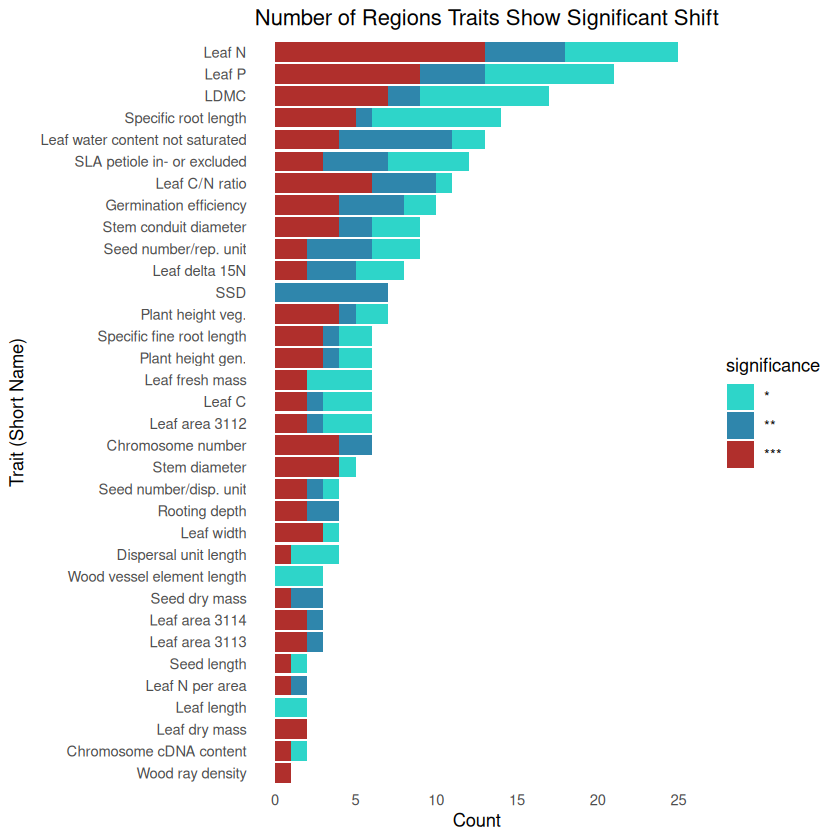

In [33]:
# plot histogram with number of times a trait (columns that start with X) have significance level in a region significance_levels
library(ggplot2)
library(tidyr)  
significance_levels_long <- significance_levels %>%
    pivot_longer(cols = -region, names_to = "trait", values_to = "significance") %>%
    filter(significance != "")  # Filter out non-significant traits
significance_levels_long <- significance_levels_long %>%
    left_join(traits, by = c("trait" = "TraitID_TRY6"))  # Join with traits to get ShortName

# Create the plot
plot <- ggplot(significance_levels_long, aes(y = reorder(ShortName, table(ShortName)[ShortName]), fill = significance)) +
    geom_bar() +
    labs(title = "Number of Regions Traits Show Significant Shift", x = "Count", y = "Trait (Short Name)") +
    theme_minimal() +
    theme(
        axis.text.y = element_text(angle = 0, hjust = 1),
        panel.grid = element_blank()  # Remove grid lines
    ) +
    scale_fill_manual(values = c("***" = "#b02f2c", "**" = "#2F86AC", "*" = "#2ed5c9", "ns" = "#fc8d62"))

# Print the plot
print(plot)
# Save the plot as a PNG image
#png(file = "~/Func_Neo_Phytes/Results/Figures/significant_traits_histogram_GBIF_wcvp.png", width = 3000, height = 1800, res = 300)
png(file = "~/Func_Neo_Phytes/Results/Figures/significant_traits_histogram_CS_wcvp.png", width = 3000, height = 1800, res = 300)
print(plot)
dev.off()
# The plot helps visualize which traits are significantly different between the "native" and "all" groups across different regions.
# --- IGNORE ---    



In [34]:
unpaired_wilcoxon_results <- unpaired_wilcoxon_results %>%
    mutate(across(
        starts_with("wilcox_p_value_X"),
        ~ p.adjust(.x, method = "BH"),
        .names = "adjusted_{col}"
    ))

In [35]:
significant_results <- unpaired_wilcoxon_results %>%
    filter(if_any(starts_with("adjusted_wilcox_p_value_X"), ~ .x <= 0.05))
significant_results
dim(significant_results)

region,wilcox_p_value_X.X3117.,wilcox_p_value_X.X14.,wilcox_p_value_X.X50.,wilcox_p_value_X.X146.,wilcox_p_value_X.X3120.,wilcox_p_value_X.X224.,wilcox_p_value_X.X297.,wilcox_p_value_X.X21.,wilcox_p_value_X.X13.,⋯,adjusted_wilcox_p_value_X.X223.,adjusted_wilcox_p_value_X.X237.,adjusted_wilcox_p_value_X.X614.,adjusted_wilcox_p_value_X.X351.,adjusted_wilcox_p_value_X.X6.,adjusted_wilcox_p_value_X.X95.,adjusted_wilcox_p_value_X.X138.,adjusted_wilcox_p_value_X.X1080.,adjusted_wilcox_p_value_X.X78.,adjusted_wilcox_p_value_X.X4.
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10_AA,3.175991e-01,3.828671e-01,2.086247e-01,3.828671e-01,3.787879e-02,7.103730e-01,5.349650e-01,7.300508e-02,4.557110e-01,⋯,6.624827e-01,0.9834955068,1.000000e+00,1.000000e+00,9.904282e-01,8.692858e-01,0.6578837829,9.337121e-01,0.9258586688,0.713378770
10_AT,6.030273e-02,4.812115e-05,7.788110e-03,1.558207e-02,7.660024e-02,1.926755e-01,8.103808e-01,7.029809e-01,1.070670e-01,⋯,1.069731e-01,0.9834955068,1.000000e+00,1.000000e+00,1.000000e+00,4.844334e-03,0.6446394104,3.027241e-01,0.1387096737,0.130951794
10_NT,3.098469e-02,1.833278e-02,2.962487e-01,6.590256e-02,2.180322e-02,8.053668e-01,7.016966e-01,6.521959e-01,4.372673e-01,⋯,6.259933e-01,0.9834955068,9.583936e-01,1.000000e+00,9.070129e-01,3.737983e-01,0.9077813340,4.461385e-02,0.5231434364,0.617075590
12_NA,1.923077e-02,1.859853e-03,2.641566e-01,1.283752e-02,2.750088e-04,6.521848e-01,5.326317e-01,1.224826e-01,2.703166e-01,⋯,9.551968e-01,0.9834955068,2.531380e-01,8.923077e-01,7.165372e-01,3.847855e-02,0.0379646798,2.658418e-03,0.1387096737,0.005926500
12_PA,9.245528e-01,5.927290e-03,2.589864e-01,4.557212e-02,4.863958e-01,2.742179e-02,1.029850e-01,4.721109e-11,6.281932e-01,⋯,6.259933e-01,0.0179241918,1.000000e+00,1.224728e-06,1.986225e-07,8.098082e-03,0.4540779924,1.009291e-02,0.0042556505,0.672964203
13_AT,3.387338e-01,2.603831e-01,7.516225e-01,5.110521e-01,1.190013e-01,8.732350e-01,2.665665e-01,7.417297e-01,6.352723e-02,⋯,6.624827e-01,0.9834955068,9.522429e-01,1.000000e+00,9.904282e-01,8.692858e-01,0.2012511741,7.389219e-01,1.0000000000,0.274683449
13_IM,1.799588e-03,7.615373e-05,3.297310e-01,2.244787e-01,1.063459e-01,1.288149e-03,9.178788e-01,4.515072e-02,9.159655e-01,⋯,5.060204e-06,0.9834955068,1.010922e-04,8.837487e-02,9.904282e-01,3.271753e-01,0.4713022996,1.272187e-01,0.0018583157,0.402919982
13_NA,3.164347e-03,2.932901e-03,3.204145e-01,1.164493e-03,7.221223e-04,8.155810e-01,9.321294e-01,2.432513e-01,1.939309e-02,⋯,9.675871e-01,0.9834955068,5.128135e-01,1.000000e+00,9.904282e-01,6.513195e-03,0.0001749934,7.741343e-06,0.3560568726,0.161636870
13_NT,8.164147e-02,3.333298e-05,1.557349e-01,9.994311e-04,2.686134e-02,7.044658e-01,8.472520e-01,4.144913e-01,6.446374e-01,⋯,9.301876e-01,0.9834955068,9.522429e-01,1.000000e+00,1.000000e+00,2.727374e-01,0.4543472673,4.629350e-01,1.0000000000,0.426672509


[1] 31 75

In [36]:
library(dplyr)
library(effsize) # For Cliff's Delta

# Initialize an empty list to store results
cliffs_delta_trait_results <- list()

# Get trait columns that start with "X"
#trait_columns <- colnames(combined_data)[startsWith(colnames(combined_data), "X")]

# Loop over all significant regions in 
for (current_region in unique(significance_levels$region)) {
    # Filter data for the current region
    filtered_data <- combined_data %>%
        filter(region == current_region & group %in% c("all", "native"))
    
    # Skip if there is insufficient data for the test
    if (nrow(filtered_data) < 2) {
        next
    }
    
    # Initialize a data frame to store results for the current region
    region_results <- data.frame(region = current_region)
    
    # Loop over each trait column
    for (trait in trait_columns) {
        # Calculate Cliff's Delta for the current trait
        cliffs_delta_trait <- tryCatch(
            {
                effsize::cliff.delta(
                    filtered_data[[trait]][filtered_data$group == "all"],
                    filtered_data[[trait]][filtered_data$group == "native"]
                )$estimate
            },
            error = function(e) NA
        )
        
        # Add the result to the region results
        region_results[[paste0("", trait)]] <- cliffs_delta_trait
    }
    
    # Store the results for the current region
    cliffs_delta_trait_results[[current_region]] <- region_results
}

# Combine all results into a single data frame and round to 2 decimal places
cliffs_delta_trait_results_df <- bind_rows(cliffs_delta_trait_results) %>%
    mutate(across(starts_with("X") | starts_with("P"), ~ round(.x, 2)))

cliffs_delta_trait_results_df


Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”
Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”


Warning message in cliff.delta.default(filtered_data[[trait]][filtered_data$group == :
“The samples are fully disjoint, using approximate Confidence Interval estimation”


region,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,X.X21.,X.X13.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10_AA,0.35,0.31,-0.43,-0.31,0.67,0.14,-0.22,-0.59,-0.27,⋯,0.39,0.14,-0.06,-0.10,0.14,-0.14,0.35,0.06,0.14,-0.27
10_AT,0.20,0.44,0.29,-0.26,0.19,-0.14,-0.03,0.04,-0.17,⋯,-0.26,0.02,-0.01,0.06,0.00,0.37,0.11,-0.17,0.24,-0.23
10_IM,NA,NA,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
10_NT,0.23,0.25,-0.11,-0.19,0.24,0.03,0.04,-0.05,-0.08,⋯,-0.13,-0.07,0.04,-0.02,-0.08,0.16,0.05,0.27,0.12,-0.10
10_PA,0.06,0.08,0.00,-0.07,0.06,-0.02,0.03,-0.01,-0.03,⋯,-0.04,0.00,0.07,0.03,0.05,0.05,0.05,0.03,0.09,-0.04
11_NA,0.01,0.02,0.00,-0.02,0.02,0.01,0.00,0.00,-0.02,⋯,-0.01,0.00,0.00,0.00,0.01,0.01,0.01,0.01,0.01,-0.01
11_PA,0.02,0.02,-0.01,-0.02,0.01,0.00,-0.01,0.00,-0.02,⋯,-0.01,0.01,0.02,0.00,0.01,0.00,0.01,0.01,0.01,0.00
12_AA,0.20,0.17,-0.10,-0.12,0.22,0.15,-0.04,-0.12,-0.13,⋯,0.02,0.03,0.19,0.00,-0.12,0.03,0.11,0.19,0.05,-0.21
12_AT,0.14,0.30,0.29,-0.22,0.18,-0.18,-0.14,0.18,-0.20,⋯,-0.04,0.07,-0.04,0.07,0.26,0.24,0.24,-0.14,0.22,-0.15


In [37]:
# filter for large and medium effects in cliffs_delta_trait_results_df
cliffs_delta_trait_results_df <- cliffs_delta_trait_results_df %>%
    filter(if_any(starts_with("X") | starts_with("P"), ~ abs(.x) >= 0.28))
cliffs_delta_trait_results_df    

region,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,X.X21.,X.X13.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10_AA,0.35,0.31,-0.43,-0.31,0.67,0.14,-0.22,-0.59,-0.27,⋯,0.39,0.14,-0.06,-0.10,0.14,-0.14,0.35,0.06,0.14,-0.27
10_AT,0.20,0.44,0.29,-0.26,0.19,-0.14,-0.03,0.04,-0.17,⋯,-0.26,0.02,-0.01,0.06,0.00,0.37,0.11,-0.17,0.24,-0.23
10_NT,0.23,0.25,-0.11,-0.19,0.24,0.03,0.04,-0.05,-0.08,⋯,-0.13,-0.07,0.04,-0.02,-0.08,0.16,0.05,0.27,0.12,-0.10
12_AT,0.14,0.30,0.29,-0.22,0.18,-0.18,-0.14,0.18,-0.20,⋯,-0.04,0.07,-0.04,0.07,0.26,0.24,0.24,-0.14,0.22,-0.15
12_NA,0.59,0.75,-0.29,-0.62,0.85,0.12,-0.17,-0.40,-0.29,⋯,0.07,-0.29,0.47,-0.36,-0.42,0.67,0.69,0.85,0.55,-0.86
12_NT,0.51,0.23,-0.03,-0.24,0.53,-0.02,-0.04,-0.26,-0.04,⋯,-0.30,-0.30,0.49,0.02,-0.26,0.15,0.29,0.46,0.08,-0.51
12_PA,0.01,0.18,0.07,-0.13,-0.05,-0.14,-0.11,0.43,-0.03,⋯,0.08,0.21,-0.01,0.36,0.38,-0.21,0.09,-0.21,0.23,0.06
13_IM,0.28,0.35,-0.09,-0.11,0.15,0.29,-0.01,-0.18,0.01,⋯,-0.48,0.10,0.41,-0.23,0.05,-0.15,0.12,0.19,0.35,-0.12
13_NA,0.19,0.19,-0.06,-0.20,0.21,0.01,-0.01,-0.07,-0.15,⋯,0.00,-0.04,0.08,0.02,-0.02,0.21,0.29,0.32,0.09,-0.12


In [38]:
library(dplyr)
library(ggplot2)
library(tidyr)

# Iterate over unique regions 
unique_regions <- unique(cliffs_delta_trait_results_df$region)

#for (i in c("CNA")) {
#for (i in c("CNA", "EAS", "EAU", "ENA", "MED", "NZ", "SAS", "SAU", "SEA", "SES", "WCE", "WNA", "NAU", "NCA", "SPO")) {
for (i in unique_regions) {  
  # Subset the data for the current region
  region_cells <- h3::polyfill(ipcc_srex[ipcc_srex$Acronym == i, ], res = 3)

  if (length(region_cells) == 0) {
    message(paste("No region cells found for region:", i))
    next
  }

  filtered_data <- combined_data %>%
    filter(h3_res3 %in% region_cells)
  
  # Step 1: Rescale trait values to a 0-1 range using min/max from "all" group
  trait_columns <- names(filtered_data)[startsWith(names(filtered_data), "X") | startsWith(names(filtered_data), "PC")]
  
  all_trait_ranges <- filtered_data %>%
    filter(group == "all") %>%
    dplyr::select(trait_columns) %>%
    summarise(across(everything(), list(min = ~min(.x, na.rm = TRUE), max = ~max(.x, na.rm = TRUE)))) %>%
    pivot_longer(cols = everything(), names_to = c("trait_name", ".value"), names_sep = "_")
  
  filtered_data <- filtered_data %>%
    pivot_longer(cols = trait_columns, names_to = "trait_name", values_to = "trait_value") %>%
    left_join(all_trait_ranges, by = "trait_name") %>%
    mutate(rescaled_value = (trait_value - min) / (max - min))
  
  # Step 2: Add ShortName from traits dataframe
  filtered_data <- filtered_data %>%
    left_join(traits, by = c("trait_name" = "TraitID_TRY6"))  # Join with traits to get ShortName
  
  
  # Step 3: Plot density curves for all traits
  density_stats <- filtered_data %>%
    group_by(group, ShortName) %>%
    summarise(
      median_value = median(rescaled_value, na.rm = TRUE),
      density_at_median = with(density(rescaled_value, na.rm = TRUE), approx(x, y, xout = median_value)$y),  # Interpolate density at median
      .groups = "drop"
    )
  f <- ggplot(filtered_data, aes(x = rescaled_value, fill = group)) +
    geom_density(alpha = 0.4, color = NA) +  # Add transparency for overlapping areas
    facet_grid(factor(ShortName, levels = c("Size spectrum (PC1)", "Economic spectrum (PC2)", sort(setdiff(unique(filtered_data$ShortName), c("Size spectrum (PC1)", "Economic spectrum (PC2)"))))) ~ ., 
           scales = "free_y", space = "fixed") +  # Use ShortName for facet labels with custom order
    geom_segment(
      data = density_stats,
      aes(
        x = median_value, xend = median_value,  # Draw the line at the median
        y = 0, yend = density_at_median,        # Line from 0 to density at median
        color = group                           # Color by group
      ),
      linewidth = 0.5
    ) +
    scale_fill_manual(values = c("native" = "#2ed5c9", "all" = "#fc8d62")) +
    labs(
        title = paste0("Trait Density Shifts in ", i),
        x = "Rescaled Trait Value",
        y = "Density",
        fill = "Group"
    ) +
    theme_minimal(base_family = "Helvetica") +  # Set base font to Lato
    theme(
      panel.grid = element_blank(),
      panel.background = element_blank(),
      legend.position = "bottom",
      strip.text.y = element_text(size = 8, face = "bold", angle = 0, hjust = 0),  # Left-align text
      strip.placement = "outside",  # Place text outside the plot area
      axis.text.y = element_blank(),  # Remove y-axis text for cleaner look
      axis.ticks.y = element_blank(),  # Remove y-axis ticks
      panel.spacing = unit(0.1, "lines")  # Reduce spacing between facets
    ) +
    coord_cartesian(xlim = c(0, 1)) +  # Set x-range from 0 to 1
    geom_text(
      data = cliffs_delta_trait_results_df %>%
      pivot_longer(cols = starts_with("X") | starts_with("P"), names_to = "trait_name", values_to = "effect_size") %>%
      filter(region == i) %>%
      left_join(traits, by = c("trait_name" = "TraitID_TRY6")),
      aes(
      x = 0.98, y = 0.48, label = paste0(effect_size),  # Adjust y position to raise text
      hjust = 1  # Align text to the right
      ),
      inherit.aes = FALSE,
      vjust = -0.5,  # Adjust vertical alignment to align with trait name label
      size = 3
    ) +
    geom_text(
      data = significance_levels %>%
      pivot_longer(cols = starts_with("X") | starts_with("P"), names_to = "trait_name", values_to = "significance") %>%
      filter(region == i) %>%
      left_join(traits, by = c("trait_name" = "TraitID_TRY6")),
      aes(
      x = 0.99, y = 0.48, label = paste0(significance),  # Adjust y position for significance values
      hjust = 0  # Align text to the right
      ),
      inherit.aes = FALSE,
      vjust = -0.5,  # Adjust vertical alignment to align with trait name label
      size = 3
    )
  print(f)
  # Test saving the plot
  output_file <- paste0("/net/home/swolf/Func_Neo_Phytes/Results/Figures/Trait_Density_Shifts_CS_wcvp", i, ".png")
  #output_file <- paste0("/net/home/swolf/Func_Neo_Phytes/Results/Figures/Trait_Density_Shifts_GBIF_wcvp", i, ".png")
  
  tryCatch({
    ggsave(filename = output_file, plot = f, width = 7, height = 16, dpi = 300, device = "png")
    message(paste("Plot saved for region:", i))
  }, error = function(e) {
    message(paste("Failed to save plot for region:", i, "Error:", e$message))
  })
}

ERROR: Error: object 'ipcc_srex' not found


In [ ]:
unmatched_traits <- setdiff(filtered_data$trait_name, traits$TraitID_TRY6)
print(unmatched_traits)

character(0)


In [ ]:
jdfg

In [ ]:
# plot denisty shifts for all regions and all traits, i.e. columns starting with "X"
library(ggplot2)
library(dplyr)
library(MASS)


perform_analysis <- function(filtered_data, f) {
  # Create a ggplot object with density plots for PC1 and PC2
  p <- ggplot(filtered_data, aes(x = PC1, y = PC2, color = group)) +
    geom_point(alpha = 0.5, size = 0.5) +
    theme_minimal() +
    labs(title = paste("Density Plot for", f$Acronym),
         x = "PC1",
         y = "PC2") +
    theme(legend.position = "right") +
    theme(panel.grid = element_blank())
  
  # Calculate density contours
  kde_all <- MASS::kde2d(filtered_data$PC1[filtered_data$group == "all"],
                         filtered_data$PC2[filtered_data$group == "all"],
                         n = 100)
  kde_native <- MASS::kde2d(filtered_data$PC1[filtered_data$group == "native"],
                            filtered_data$PC2[filtered_data$group == "native"],
                            n = 100)
  
  df_kde_all <- data.frame(expand.grid(PC1 = kde_all$x, PC2 = kde_all$y), z = as.vector(kde_all$z))
  df_kde_native <- data.frame(expand.grid(PC1 = kde_native$x, PC2 = kde_native$y), z = as.vector(kde_native$z))
  
  # Add density contours to the plot
  p +
    geom_contour(data = df_kde_all, aes(x = PC1, y = PC2, z = z),
                 breaks = kde_all$cutoff,
                 color = "#fc8d62",
                 linewidth = 1) +
    geom_contour(data = df_kde_native, aes(x = PC1, y = PC2, z = z),
                 breaks = kde_native$cutoff,
                 color = "#2ed5c9",
                 linewidth = 1) +
    geom_hline(yintercept = 0, color = "lightgrey", linewidth = 0.3) +
    geom_vline(xintercept = 0, color = "lightgrey", linewidth = 0.3) +
    theme_minimal() +
    theme(legend.position = "right") +
    labs(title = paste("Density Contours for", f$Acronym),
         x = "PC1",
         y = "PC2") +
    theme(panel.grid = element_blank())

    p
}  


for (i in unique(ipcc_srex$Acronym)) {
  f <- ipcc_srex[ipcc_srex$Acronym == i, ]
  region_cells <- h3::polyfill(f, res = 3)
  
  # Filter the combined_data for the current region
  filtered_data <- combined_data %>%
    filter(h3_res3 %in% region_cells)
  
  sub_plot <- perform_analysis(filtered_data, f)
  
  pdf(file = paste0("~/Func_Neo_Phytes/Results/Figures/pca_", i, "_densities_traitshift.pdf"),
      width = 10, height = 7)
  print(sub_plot)
  dev.off()
}




Attaching package: ‘MASS’


The following object is masked from ‘package:dplyr’:

    select




Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”
Warning message in min(x):
“no non-missing arguments to min; returning Inf”
Warning message in max(x):
“no non-missing arguments to max; returning -Inf”


ERROR: Error in MASS::kde2d(filtered_data$PC1[filtered_data$group == "all"], : only finite values are allowed in 'lims'


In [ ]:
library(dplyr)

for (i in unique(ipcc_srex$Acronym)) {
  
  # Subset the data for the current region
  long_df_native_region <- long_df_native[long_df_native$region == i, ]
  long_df_all_region <- long_df_all[long_df_all$region == i, ]
  percent_change_region <- percent_change[percent_change$region == i, ]
  
  # Combine native and all data for p-value calculations
  combined_df <- bind_rows(long_df_native_region, long_df_all_region)
  combined_df <- combined_df %>%
    filter(!is.na(mean_value), !is.na(median_value))
  
  # Step 1: Calculate p-values and filter significant traits
  p_values <- compare_distributions_across_regions(combined_df)
  
  # Step 2: Filter significant traits
  significant_traits <- p_values %>%
    filter(wilcox_p_BH < 0.05) %>%
    pull(trait_name)
  
  # Step 3: Filter percent change and select top 5 traits
  percent_change_top <- percent_change_region %>%
    filter(trait_name %in% significant_traits) %>%
    mutate(abs_change = abs(mean_value)) %>%
    arrange(desc(abs_change)) %>%
    slice_head(n = 5)
  
  # Step 4: Join p-values with the top traits for annotations
  # percent_change_top <- percent_change_top %>%
  #   left_join(p_values %>% dplyr::select(trait_name, signif), by = "trait_name")
  percent_change_top <- merge(percent_change_top, p_values[, c("trait_name", "signif")], by = "trait_name", all.x = TRUE)

  
  # Get the names of the top traits
  top_traits <- percent_change_top$trait_name
  
  # Filter native and all data for plotting
  long_df_native_region <- long_df_native_region %>%
    filter(trait_name %in% top_traits)
  long_df_all_region <- long_df_all_region %>%
    filter(trait_name %in% top_traits)
  
  # Step 5: Rescale values to a 0-1 range using min/max from "all" species
  all_trait_ranges <- long_df_all_region %>%
    group_by(trait_name) %>%
    summarize(
      min_value = min(mean_value, na.rm = TRUE),
      max_value = max(mean_value, na.rm = TRUE),
      .groups = "drop"
    )
  
  long_df_all_region <- long_df_all_region %>%
    left_join(all_trait_ranges, by = "trait_name") %>%
    mutate(rescaled_value = (mean_value - min_value) / (max_value - min_value))
  
  long_df_native_region <- long_df_native_region %>%
    left_join(all_trait_ranges, by = "trait_name") %>%
    mutate(rescaled_value = (mean_value - min_value) / (max_value - min_value))
  
  # Combine rescaled data
  combined_df <- bind_rows(long_df_all_region, long_df_native_region)
  
  # Compute the mean (or median) for each trait and status
  mean_values <- combined_df %>%
    group_by(trait_name, status) %>%
    summarize(mean_value_total = mean(rescaled_value, na.rm = TRUE), .groups = "drop")
  
  # Step 6: Calculate the percent change from native to all
  mean_values_native <- mean_values %>% filter(status == "native") %>%
    select(trait_name, mean_value_total) %>%
    rename(mean_value_native = mean_value_total)

  mean_values_all <- mean_values %>% filter(status == "all") %>%
    select(trait_name, mean_value_total) %>%
    rename(mean_value_all = mean_value_total)

  # Join native and all mean values on trait_name
  mean_values_combined <- left_join(mean_values_native, mean_values_all, by = "trait_name")

  # Calculate the percent change
  mean_values_combined <- mean_values_combined %>%
    mutate(
      percent_change_total = ((mean_value_all - mean_value_native) / abs(mean_value_native)) * 100
    )

  # Merge percent change back into the mean_values dataframe
  mean_values <- left_join(mean_values, mean_values_combined %>% dplyr::select(trait_name, percent_change_total), by = "trait_name")
  stats <- left_join(mean_values, percent_change_top %>% dplyr::select(trait_name, mean_value, signif), by = "trait_name")
  
  # Step 7: Compute the density for each trait and status
  densities <- combined_df %>%
    group_by(trait_name, status) %>%
    do(density_data = density(.$rescaled_value, na.rm = TRUE)) %>%
    ungroup()
  
  # Get the density at the mean_value by finding the closest x-value to the mean_value
  densities_at_mean <- densities %>%
    rowwise() %>%
    mutate(
      density_at_mean = {
        closest_idx <- which.min(abs(density_data$x - mean_values$mean_value_total[mean_values$trait_name == trait_name & mean_values$status == status]))
        density_data$y[closest_idx]
      }
    )
  
  # Merge the mean values with the density at the mean for proper line placement
  stats <- left_join(stats, densities_at_mean, by = c("trait_name", "status"))

  png(file = paste0("~/Func_Neo_Phytes/Results/Figures/Top_Trait_Density_Shifts/", i, "s200r4try6_05_mean.png"), width = 1600, height = 1200, res = 300)
  
  # Plot with density curves, mean lines, and annotations
  f <- ggplot(combined_df, aes(x = rescaled_value, fill = status)) +
    geom_density(alpha = 0.4, color = NA) +
    facet_grid(trait_name ~ ., scales = "free_y") +  # Facet by trait_name
    geom_segment(
      data = stats, 
      aes(
        x = mean_value_total, xend = mean_value_total,  # Draw the line at the mean
        y = 0, yend = density_at_mean,     # Line from 0 to density at mean
        color = status                     # Color by status (native vs all)
      ), 
      linewidth = 0.5
    ) +
      scale_fill_manual(values = c("native" = "#2ed5c9", "all" = "#fc8d62")) +  # Match density fill colors
#scale_fill_manual(values = c("native" = "#a3e5dd", "all" = "#fcc8a4"))

    scale_color_manual(values = c("native" = "#2ed5c9", "all" = "#fc8d62")) +  # Set color for native and all
    geom_text(
      data = stats, 
      aes(
        x = 0.75, y = 0.3, 
        label = paste0(trait_name, "\n", ifelse(percent_change_total > 0, "+", ""), round(percent_change_total, 0), "% ", signif,  "\n", ifelse(percent_change_total > 0, "+", ""), round(mean_value, 0), "% ")
      ), 
      vjust = -0.1, size = 3, hjust = 0, color = "black"
    ) +
    # geom_text(
    #   data = stats, 
    #   aes(
    #     x = 0.9, y = 0.3, 
    #     label = paste0("Total PC: ", round(percent_change_total, 1), "%"),
    #     color = "black"
    #   ),
    #   vjust = -0.8, size = 3, hjust = 0  # Adjust position for new label
    # ) +
    labs(
      title = paste0("Top Traits in ", i, " with Significant Differences"),
      x = "Rescaled Trait Value",
      y = "Relative Density",
      fill = "Status",
      color = "Status"
    ) +
    theme_minimal() +
    theme(
      axis.text.y = element_blank(),
      axis.ticks.y = element_blank(),
      panel.grid = element_blank(),
      panel.background = element_blank(),
      legend.position = "left",
      strip.text = element_text(size = 10, face = "bold")
    )  +
  coord_cartesian(xlim = c(0, 1.2))
  
  # Display plot
  print(f)
  dev.off()
  
}